# 01 · Análisis exploratorio (EDA) — TweetToxic

Competencia de Kaggle **TweetToxic** (Maestría en IA, Javeriana): clasificación **multietiqueta** de tuits en español.

| Etiqueta | Significado |
|---|---|
| **HS** | *Hate speech*: el tuit contiene discurso de odio |
| **TR** | *Target*: el odio va dirigido contra una persona concreta (1) o no (0) |
| **AG** | *Aggressiveness*: el tuit es agresivo |

- **Métrica:** F1-score. Aún no sabemos si se promedia en modo *macro* o *micro* entre las tres columnas, así que aquí no se asume ninguno.
- **Reglas:** no se permiten modelos, embeddings ni clasificadores preentrenados. Sí BoW, TF-IDF, Word2Vec entrenado por nosotros y léxicos o corpus externos citados.
- **Alcance de este notebook:** solo exploración. No se entrena ningún modelo predictivo; la única excepción es la validación adversarial de la sección 8, que es un diagnóstico.

**Convenciones de la serie de notebooks** (las fija este primero):
- La configuración compartida vive en `notebooks/common.py`: `SEED`, `LABELS`, rutas (`DATA_DIR`, `FIGURES_DIR`), `load_train()` y `load_test()`.
- Todo lo aleatorio usa `SEED`. Los archivos de `data/` nunca se modifican.
- Las figuras se guardan en `reports/figures/` con el prefijo del notebook (`01_...png`).
- Markdown y comentarios en español; nombres de variables en inglés.

## 1. Configuración y carga

Importamos librerías, fijamos la semilla, registramos versiones (para reproducibilidad) y cargamos los datos con las funciones de `common.py`. Después revisamos tamaño, tipos, valores nulos y duplicados exactos.

In [1]:
import platform
import re
import unicodedata
from collections import Counter

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display

from common import DATA_DIR, FIGURES_DIR, LABELS, SEED, TEST_PATH, TRAIN_PATH, load_test, load_train

np.random.seed(SEED)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Estilo de gráficos y colores consistentes en todo el notebook
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
CLASS_COLORS = {0: "#a3a29c", 1: "#e34948"}                      # clase negativa (gris) / positiva (rojo)
LABEL_COLORS = {"HS": "#2a78d6", "TR": "#eb6834", "AG": "#1baf7a"}  # una por etiqueta
SPLIT_COLORS = {"train": "#2a78d6", "test": "#4a3aa7"}

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 200)


def savefig(fig, name):
    """Guarda la figura en reports/figures/ con el prefijo de este notebook."""
    fig.savefig(FIGURES_DIR / f"01_{name}.png", dpi=120, bbox_inches="tight")


print(f"Python      {platform.python_version()}")
for lib in (pd, np, matplotlib, sns, sklearn):
    print(f"{lib.__name__:<11} {lib.__version__}")
print(f"SEED = {SEED} | DATA_DIR = {DATA_DIR}")

Python      3.14.6
pandas      3.0.6
numpy       2.5.3
matplotlib  3.11.2
seaborn     0.13.2
sklearn     1.9.1
SEED = 42 | DATA_DIR = /Users/juansebastian/Documents/Repositorios/5. NLP/TweetToxic/data


In [2]:
train = load_train()
test = load_test()  # None si data/toxic_test.csv no existe
HAS_TEST = test is not None

print(f"Train: {train.shape[0]} filas x {train.shape[1]} columnas")
if HAS_TEST:
    print(f"Test:  {test.shape[0]} filas x {test.shape[1]} columnas")
display(train.head())

Train: 1731 filas x 5 columnas
Test:  1154 filas x 2 columnas


,id,text,HS,TR,AG
0,20430,@SomosRedSaime amigos SAIME mi nombre es walter perez V-13.899.989 wperez001@gmail.com y desde el 16/03/2017 que fui a cita aun no me imprimen el pasaporte...,0,0,0
1,22434,Preferan enfrentar los peligros de regresar a su hogar antes que ser encarcelados en estas condiciones seal la organizacin que tambin demand a la polica mig...,0,0,0
2,23930,@srtaalegre_ Siiii jajjajajajjajajaja yo te iba a ensear pero vivs lejos nde puta.,0,0,0
3,20412,@anaisbernal Esta es la justicia en espaa para estos indeseables una puta verguenza,0,0,0
4,23531,Escucho Arabe y me dan ms ganas de estar en cheboli muviendo el orto con mis amigas we,0,0,0


### ¿Cuántas filas tiene realmente el CSV?

Con `sep=";"` se leen 1731 filas, pero un visor de archivos reportó 1228. Para resolverlo contamos las líneas físicas del archivo y buscamos filas con formato anómalo (comillas sueltas o `;` dentro del texto).

In [3]:
raw_lines = TRAIN_PATH.read_bytes().decode("latin-1").splitlines()
print(f"Líneas físicas del archivo: {len(raw_lines)} (1 encabezado + {len(raw_lines) - 1} filas)")
print(f"Filas leídas por pandas:     {len(train)}")

# Líneas con más de 4 ';' => el texto contiene ';' (va entre comillas, pandas lo resuelve bien)
n_sep = pd.Series([line.count(";") for line in raw_lines[1:]])
print(f"Líneas con ';' dentro del texto: {(n_sep > 4).sum()}")

# Líneas que no empiezan por un id numérico
bad = [(i + 1, line[:110]) for i, line in enumerate(raw_lines) if i > 0 and not re.match(r"\d+;", line)]
print(f"Líneas que no empiezan por 'id;': {len(bad)}")
for lineno, line in bad:
    print(f"  línea {lineno} (fila de datos n.º {lineno - 1}): {line}...")

Líneas físicas del archivo: 1732 (1 encabezado + 1731 filas)
Filas leídas por pandas:     1731
Líneas con ';' dentro del texto: 12
Líneas que no empiezan por 'id;': 1
  línea 1229 (fila de datos n.º 1228): """22621";"""""El mejor Rallo: el que se mete en jardines con sus lectores habituales. """"""""Por qu Pablo Ca...


**Interpretación:** El archivo tiene 1732 líneas físicas (encabezado + 1731 filas) y pandas lee **1731 filas**, así que ningún texto contiene saltos de línea. Las 12 líneas con `;` dentro del texto van entre comillas y se leen bien. La única anomalía está en la línea 1229, donde el id viene como `"""22621"` (con comillas sobrantes); `load_train()` lo limpia y lo deja en `22621`. Esa línea es la **fila de datos n.º 1228**, así que lo más probable es que el visor se confundiera con esas comillas justo ahí: dejaría de contar o uniría el resto del archivo en una sola fila. Eso explicaría que reportara 1228. El train tiene 1731 filas válidas.

In [4]:
print("Tipos:")
print(train.dtypes.to_string())
print("\nNulos por columna (train):", train.isna().sum().to_dict())
print("Textos vacíos (train):", (train["text"].str.strip() == "").sum())
print("ids duplicados (train):", train["id"].duplicated().sum())
print("Textos duplicados exactos (train):", train["text"].duplicated().sum())
print("Valores de las etiquetas:", {c: sorted(train[c].unique()) for c in LABELS})

if HAS_TEST:
    print("\nNulos por columna (test):", test.isna().sum().to_dict())
    print("ids duplicados (test):", test["id"].duplicated().sum())
    dup_test = test[test["text"].duplicated(keep=False)]
    print(f"Textos duplicados exactos (test): {test['text'].duplicated().sum()}")
    display(dup_test["text"].value_counts().to_frame("veces"))
    print("ids compartidos train-test:", len(set(train["id"]) & set(test["id"])))
    print("Textos idénticos train-test:", len(set(train["text"]) & set(test["text"])))

Tipos:
id      int64
text      str
HS      int64
TR      int64
AG      int64

Nulos por columna (train): {'id': 0, 'text': 0, 'HS': 0, 'TR': 0, 'AG': 0}
Textos vacíos (train): 0
ids duplicados (train): 0
Textos duplicados exactos (train): 0
Valores de las etiquetas: {'HS': [np.int64(0), np.int64(1)], 'TR': [np.int64(0), np.int64(1)], 'AG': [np.int64(0), np.int64(1)]}

Nulos por columna (test): {'id': 0, 'text': 0}
ids duplicados (test): 0
Textos duplicados exactos (test): 5


,veces
text,
#¿NOMBRE?,6


ids compartidos train-test: 0
Textos idénticos train-test: 0


**Interpretación:** El train no tiene nulos, textos vacíos, ids repetidos ni textos duplicados exactos, y las etiquetas valen solo 0 o 1. El test (1154 filas) tampoco tiene nulos ni ids repetidos, pero **6 filas tienen como texto `#¿NOMBRE?`**: el contenido original se perdió (ver sección 4) y esas filas son los 5 duplicados que aparecen. Train y test no comparten ids ni textos exactos.

## 2. Distribución de etiquetas

Medimos cuántos tuits son positivos en cada etiqueta y qué combinaciones de las tres aparecen. Esto importa por dos razones:

1. **Desbalance:** el F1 de la clase positiva es sensible a cuántos positivos hay; un umbral de decisión de 0.5 puede no ser el óptimo.
2. **Dependencia entre etiquetas:** si una etiqueta implica otra (p. ej. TR=1 ⇒ HS=1), conviene modelarlas de forma conjunta o forzar la coherencia en la predicción.

In [5]:
label_summary = pd.DataFrame({
    "positivos": train[LABELS].sum(),
    "negativos": (1 - train[LABELS]).sum(),
    "% positivos": (100 * train[LABELS].mean()).round(1),
})
display(label_summary)

combo = train[LABELS].astype(str).agg("".join, axis=1)
combo_counts = combo.value_counts().rename_axis("HS TR AG").to_frame("n")
combo_counts["%"] = (100 * combo_counts["n"] / len(train)).round(1)
display(combo_counts)
print("Combinaciones posibles: 8 | observadas:", combo.nunique(),
      "| ausentes:", sorted(set(f"{i:03b}" for i in range(8)) - set(combo)))

,positivos,negativos,% positivos
HS,756,975,43.7
TR,519,1212,30.0
AG,662,1069,38.2


,n,%
HS TR AG,,
000,949,54.8
111,491,28.4
101,145,8.4
100,92,5.3
110,28,1.6
001,26,1.5


Combinaciones posibles: 8 | observadas: 6 | ausentes: ['010', '011']


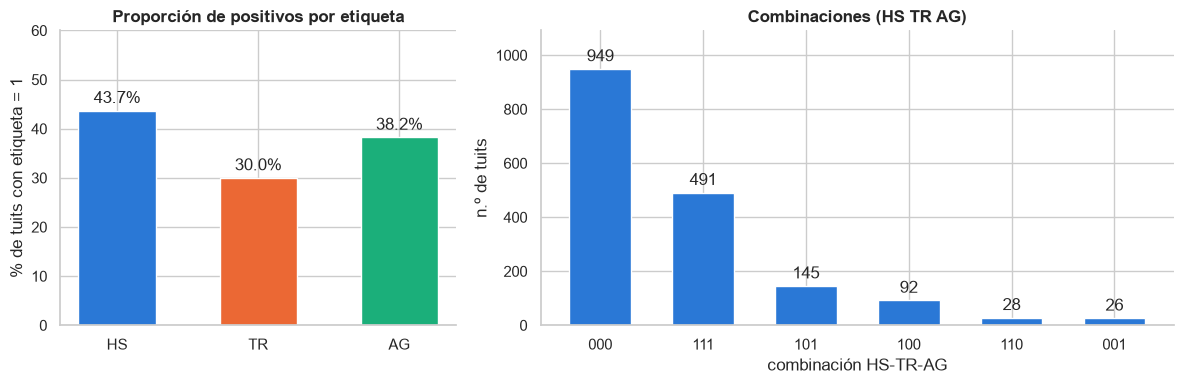

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.6]})

ax = axes[0]
pct = 100 * train[LABELS].mean()
bars = ax.bar(LABELS, pct, color=[LABEL_COLORS[c] for c in LABELS], width=0.55)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in pct], padding=3)
ax.set(title="Proporción de positivos por etiqueta", ylabel="% de tuits con etiqueta = 1", ylim=(0, 60))

ax = axes[1]
order = combo_counts.index
bars = ax.bar(order, combo_counts["n"], color="#2a78d6", width=0.6)
ax.bar_label(bars, padding=3)
ax.set(title="Combinaciones (HS TR AG)", xlabel="combinación HS-TR-AG", ylabel="n.º de tuits",
       ylim=(0, combo_counts["n"].max() * 1.15))
fig.tight_layout()
savefig(fig, "label_distribution")
plt.show()

**Interpretación:** Se confirman los porcentajes preliminares: **HS 43.7% (756), TR 30.0% (519), AG 38.2% (662)**. Las combinaciones coinciden exactamente con las anotadas: 000 = 949 (54.8%), 111 = 491 (28.4%), 101 = 145 (8.4%), 100 = 92, 110 = 28, 001 = 26. Las combinaciones 010 y 011 (TR=1 sin HS) no aparecen nunca. Ninguna etiqueta está muy desbalanceada; la más minoritaria es TR, con un 30% de positivos.

### Correlación entre etiquetas y jerarquía

- El **coeficiente phi (φ)** es la correlación de Pearson aplicada a dos variables binarias: 0 = independientes, 1 = siempre coinciden.
- Las **tablas de contingencia** cruzan dos etiquetas y cuentan cada combinación. A partir de ellas se calculan probabilidades condicionadas, p. ej. P(HS=1 | TR=1) = proporción de tuits con odio entre los dirigidos.

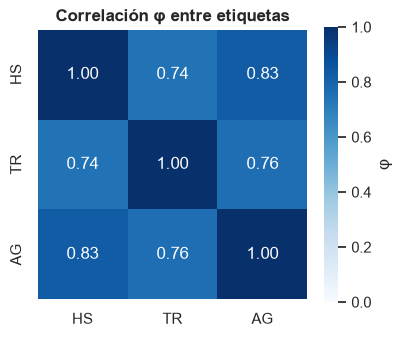


HS (filas) vs TR (columnas)


TR,0,1,total
HS,,,
0,975,0,975
1,237,519,756
total,1212,519,1731



HS (filas) vs AG (columnas)


AG,0,1,total
HS,,,
0,949,26,975
1,120,636,756
total,1069,662,1731


In [7]:
phi = train[LABELS].corr()  # Pearson sobre binarias = phi

fig, ax = plt.subplots(figsize=(4.2, 3.5))
sns.heatmap(phi, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True, cbar_kws={"label": "φ"}, ax=ax)
ax.set_title("Correlación φ entre etiquetas")
fig.tight_layout()
savefig(fig, "label_phi")
plt.show()

for other in ["TR", "AG"]:
    ct = pd.crosstab(train["HS"], train[other], margins=True, margins_name="total")
    print(f"\nHS (filas) vs {other} (columnas)")
    display(ct)

In [8]:
def cond(a, va, b, vb):
    """P(a = va | b = vb) y el n.º de casos con b = vb."""
    sub = train[train[b] == vb]
    return (sub[a] == va).mean(), len(sub)

rows = [
    ("TR=1 y HS=0", int(((train.TR == 1) & (train.HS == 0)).sum())),
    ("AG=1 y HS=0", int(((train.AG == 1) & (train.HS == 0)).sum())),
    ("TR=1 y AG=0", int(((train.TR == 1) & (train.AG == 0)).sum())),
]
display(pd.DataFrame(rows, columns=["caso", "n"]))

probs = {
    "P(HS=1 | TR=1)": cond("HS", 1, "TR", 1),
    "P(HS=1 | AG=1)": cond("HS", 1, "AG", 1),
    "P(AG=1 | HS=1)": cond("AG", 1, "HS", 1),
    "P(TR=1 | HS=1)": cond("TR", 1, "HS", 1),
    "P(AG=1 | TR=1)": cond("AG", 1, "TR", 1),
    "P(AG=1 | HS=1, TR=0)": ((train.query("HS == 1 and TR == 0").AG == 1).mean(), len(train.query("HS == 1 and TR == 0"))),
}
display(pd.DataFrame([(k, round(v[0], 3), v[1]) for k, v in probs.items()], columns=["probabilidad", "valor", "n condicionante"]))

,caso,n
0,TR=1 y HS=0,0
1,AG=1 y HS=0,26
2,TR=1 y AG=0,28


,probabilidad,valor,n condicionante
0,P(HS=1 | TR=1),1.000,519
1,P(HS=1 | AG=1),0.961,662
2,P(AG=1 | HS=1),0.841,756
3,P(TR=1 | HS=1),0.687,756
4,P(AG=1 | TR=1),0.946,519
5,"P(AG=1 | HS=1, TR=0)",0.612,237


**Interpretación:** Se confirma la jerarquía:
- **TR=1 ⇒ HS=1 sin excepciones** (0 casos de 519).
- AG=1 ⇒ HS=1 en el 96.1% de los casos; las **26 excepciones** se analizan justo debajo.
- Dentro de HS=1, AG=1 en el 84.1% y TR=1 en el 68.7%. Además, cuando hay TR casi siempre hay AG: P(AG=1 | TR=1) = 0.946.

Las correlaciones φ son altas (HS–AG 0.83, TR–AG 0.76, HS–TR 0.74), así que las tres etiquetas no son independientes. TR y AG funcionan como **subcategorías de HS**: tiene sentido un esquema en cascada o, como mínimo, forzar la coherencia (si HS=0, entonces TR=0 y AG=0).

### ¿De dónde salen los casos AG=1 con HS=0?

Al revisar a mano los 26 tuits con combinación `001` vimos que casi todos son titulares de noticias sin ninguna agresividad y que su texto lleva comillas duplicadas (`""...""`) o un `;`. Un escritor de CSV solo pone un campo entre comillas cuando contiene el separador (`;`) o comillas (`"`). Por eso comprobamos si **estar entre comillas en el CSV** se relaciona con las etiquetas.

In [9]:
# Campo de texto entre comillas en el archivo crudo (las líneas del CSV están en el mismo orden que las filas)
raw_text_field = pd.Series([line.split(";", 1)[1] for line in raw_lines[1:]])
train["csv_quoted"] = raw_text_field.str.startswith('"').values
# Comprobación: coincide con la regla del escritor de CSV (el texto contiene ';' o '"')
assert (train["csv_quoted"] == train["text"].str.contains(r'[;"]')).all()

combo_q = pd.crosstab(combo, train["csv_quoted"]).rename(columns={False: "sin comillas", True: "entre comillas"})
combo_q.index.name = "HS TR AG"
display(combo_q)
q = train["csv_quoted"]
print(f"Tuits entre comillas en el CSV: {q.sum()} | con AG=1: {train.loc[q, 'AG'].sum()} "
      f"({100 * train.loc[q, 'AG'].mean():.0f}%) vs {100 * train.loc[~q, 'AG'].mean():.1f}% en el resto")
print(f"HS=1 entre comillas: {100 * train.loc[q, 'HS'].mean():.1f}% vs {100 * train.loc[~q, 'HS'].mean():.1f}% en el resto")
print(f"Casos AG=1 y HS=0 explicados por las comillas: {((train.AG == 1) & (train.HS == 0) & q).sum()} de "
      f"{((train.AG == 1) & (train.HS == 0)).sum()}")
phi_unq = train.loc[~q, LABELS].corr()
print(f"φ(HS, AG): {phi.loc['HS', 'AG']:.2f} con todas las filas -> {phi_unq.loc['HS', 'AG']:.2f} sin las filas entre comillas")
if HAS_TEST:
    q_test = test["text"].str.contains(r'[;"]')
    print(f"Tuits del test que estarían entre comillas: {q_test.sum()} ({100 * q_test.mean():.1f}%)")
display(train.loc[q & (train.HS == 0), ["text", "HS", "TR", "AG"]].head(6))

csv_quoted,sin comillas,entre comillas
HS TR AG,,
000,949,0
001,0,26
100,92,0
101,124,21
110,28,0
111,487,4


Tuits entre comillas en el CSV: 51 | con AG=1: 51 (100%) vs 36.4% en el resto
HS=1 entre comillas: 49.0% vs 43.5% en el resto
Casos AG=1 y HS=0 explicados por las comillas: 26 de 26
φ(HS, AG): 0.83 con todas las filas -> 0.86 sin las filas entre comillas
Tuits del test que estarían entre comillas: 34 (2.9%)


,text,HS,TR,AG
70,"""""Es bien naco decirle """"""""gabacho"""""""" a los """"""""yunaites""""""""""""",0,0,1
71,"""""Una eurodiputada del BNG desea """"""""violaciones mltiples"""""""" a Casado para que entienda a los inmigrantes https://t.co/pqOHZaE0GU""""",0,0,1
100,"""""Una nueva pelcula de """"""""wini pu"""""""" ??? Necesitamos que las bolsas de cereal traigan cierre ziploc no esas jaladas de osos mayates.""""",0,0,1
115,"""""PSOE-A asegura que en materia de inmigracin el Gobierno de Snchez ha hecho """"""""ms en dos meses que Rajoy en siete aos"""""""" https://t.co/icNBrotefs""""",0,0,1
134,"""""@CNMBrandon Recientemente los medios de comunicacin han difundido las imgenes del """"""""salto"""""""" a la valla de Ceuta (ciudad espaola en frica). Algunos med...",0,0,1
153,Y pensar que la perra desgraciada me muerde cuando trataba de ensearle trucos o a saltar la cuerda. ;_;,0,0,1


**Interpretación:** Este es un hallazgo importante. **Las 51 filas cuyo texto aparece entre comillas en el CSV tienen todas AG=1** (100%, frente al 36.4% del resto), y **los 26 casos con AG=1 y HS=0 están todos entre ellas**. Esos 26 son titulares y frases neutras sin agresividad ("Una eurodiputada del BNG desea...", "Y pensar que la perra desgraciada me muerde...", que habla de un perro). En cambio, HS no parece afectado (49.0% de positivos entre comillas frente a 43.5% fuera).

Todo apunta a un **artefacto en la generación del archivo**: a las filas que tuvieron que ir entre comillas se les puso AG=1. Si se excluyen, la jerarquía es estricta (AG=1 ⇒ HS=1 sin excepciones) y φ(HS, AG) sube de 0.83 a 0.86. El artefacto también afecta a 21 de los 145 casos `101` y a 4 de los `111`, cuyo AG real no podemos saber.

En el test, 34 tuits (2.9%) contienen `;` o `"`. Si su etiqueta oculta se generó igual, también tendrán AG=1. Cómo tratar esto es una decisión abierta (sección 9).

## 3. Características superficiales del texto

Medimos rasgos que no dependen del vocabulario: longitud, mayúsculas, signos de puntuación, menciones (`@usuario`), URLs, hashtags, retuits (`RT`), alargamientos (una letra repetida 3 o más veces, como *siiii*) y risas (*jaja*, *jeje*, *jsjs*). Si un rasgo difiere mucho entre clases es una señal barata para el modelo; si no difiere, no vale la pena añadirlo como *feature*.

Los rasgos de estilo (mayúsculas, alargamientos, risas) se calculan sobre el texto **sin URLs ni menciones**, para que los nombres de usuario y los enlaces no los contaminen.

In [10]:
# Expresiones regulares reutilizadas en el resto del notebook
RE_URL = re.compile(r"https?://\S+|www\.\S+")
RE_MENTION = re.compile(r"(?<![\w.])@\w+")          # evita los '@' de los correos electrónicos
RE_HASHTAG = re.compile(r"(?<!\w)#\w+")
RE_RT = re.compile(r"\bRT\b")
RE_ELONG = re.compile(r"([^\W\d_])\1{2,}")          # una letra repetida 3+ veces (siiii, noooo)
RE_PUNCT_REP = re.compile(r"([!?.])\1{2,}")          # signo repetido 3+ veces (!!!, ???, ...)
# Risas: token con 2+ 'j' formado solo por j/a/e/i/o/s/h/k (jaja, jajjaja, JAHAJA, jsjs) o 'xd'
RE_LAUGH = re.compile(r"(?i)\b(?=[a-z]*j[a-z]*j)[jaeioshk]{4,}\b|\bx+d+\b")


def strip_handles(text):
    """Quita URLs y menciones (para medir estilo y vocabulario)."""
    return RE_MENTION.sub(" ", RE_URL.sub(" ", text))


def contains(s: pd.Series, rx: re.Pattern) -> pd.Series:
    return s.map(lambda t: rx.search(t) is not None)


def text_features(s: pd.Series) -> pd.DataFrame:
    clean = s.map(strip_handles)
    letters = clean.str.count(r"[^\W\d_]")
    upper = clean.str.count(r"[A-ZÁÉÍÓÚÑÜ]")
    return pd.DataFrame({
        "n_chars": s.str.len(),
        "n_words": s.str.split().str.len(),
        "upper_ratio": (upper / letters.replace(0, np.nan)).fillna(0),
        "n_excl": s.str.count("!"),
        "n_quest": s.str.count(r"\?"),
        "n_mentions": s.str.count(RE_MENTION.pattern),
        "starts_mention": s.str.match(r"\s*@\w+"),
        "n_urls": s.str.count(RE_URL.pattern),
        "n_hashtags": s.str.count(RE_HASHTAG.pattern),
        "has_rt": contains(s, RE_RT),
        "has_elong": contains(clean, RE_ELONG),
        "has_punct_rep": contains(clean, RE_PUNCT_REP),
        "has_laugh": contains(clean, RE_LAUGH),
    })


feat = text_features(train["text"])
feat["has_mention"] = feat["n_mentions"] > 0
feat["has_url"] = feat["n_urls"] > 0
feat["has_hashtag"] = feat["n_hashtags"] > 0
feat["has_excl"] = feat["n_excl"] > 0
feat["has_quest"] = feat["n_quest"] > 0
feat["mostly_upper"] = feat["upper_ratio"] > 0.5
train_feat = pd.concat([train, feat], axis=1)

prevalence = (100 * feat[["has_mention", "starts_mention", "has_url", "has_hashtag", "has_rt", "has_elong",
                          "has_punct_rep", "has_laugh", "has_excl", "has_quest", "mostly_upper"]].mean()).round(1)
display(prevalence.to_frame("% de tuits (train)"))
display(feat[["n_chars", "n_words", "upper_ratio", "n_mentions", "n_urls", "n_hashtags"]].describe().round(2).T)

,% de tuits (train)
has_mention,47.4
starts_mention,40.5
has_url,31.2
has_hashtag,9.3
has_rt,0.5
has_elong,3.6
has_punct_rep,10.9
has_laugh,6.3
has_excl,8.7
has_quest,9.1


,count,mean,std,min,25%,50%,75%,max
n_chars,1731.0,104.31,59.92,6.0,59.00,91.00,131.00,306.0
n_words,1731.0,17.12,10.23,1.0,10.00,15.00,23.00,57.0
upper_ratio,1731.0,0.12,0.25,0.0,0.02,0.04,0.08,1.0
n_mentions,1731.0,0.72,1.07,0.0,0.00,0.00,1.00,16.0
n_urls,1731.0,0.33,0.52,0.0,0.00,0.00,1.00,2.0
n_hashtags,1731.0,0.17,0.76,0.0,0.00,0.00,0.00,15.0


El hallazgo preliminar hablaba de ~19% de alargamientos. Ese porcentaje depende mucho de la definición, así que comparamos varias:

In [11]:
any_rep_raw = contains(train["text"], re.compile(r"(.)\1{2,}"))
elong_defs = pd.Series({
    "letra repetida 3+ veces, sin URLs ni menciones (definición usada)": feat["has_elong"].mean(),
    "letra repetida 3+ veces, texto crudo (incluye URLs y @usuarios)": contains(train["text"], RE_ELONG).mean(),
    "cualquier carácter repetido 3+ veces, texto crudo": any_rep_raw.mean(),
    "   · con espacios repetidos": contains(train["text"], re.compile(r" {3,}")).mean(),
    "   · con signos repetidos (!!!, ???, ...)": contains(train["text"], RE_PUNCT_REP).mean(),
    "   · con dígitos repetidos (400.000)": contains(train["text"], re.compile(r"(\d)\1{2,}")).mean(),
    "   · con comillas repetidas (artefacto del CSV)": contains(train["text"], re.compile(r'"{3,}')).mean(),
    "risa (jaja, jeje, jsjs, xd)": feat["has_laugh"].mean(),
    "alargamiento de letra o risa": (feat["has_elong"] | feat["has_laugh"]).mean(),
})
display((100 * elong_defs).round(1).to_frame("% de tuits"))

,% de tuits
"letra repetida 3+ veces, sin URLs ni menciones (definición usada)",3.6
"letra repetida 3+ veces, texto crudo (incluye URLs y @usuarios)",5.2
"cualquier carácter repetido 3+ veces, texto crudo",19.3
· con espacios repetidos,1.7
"· con signos repetidos (!!!, ???, ...)",10.9
· con dígitos repetidos (400.000),1.1
· con comillas repetidas (artefacto del CSV),2.2
"risa (jaja, jeje, jsjs, xd)",6.3
alargamiento de letra o risa,9.2


**Interpretación:** Se confirma la abundancia de **menciones (47.4% de los tuits; 40.5% empiezan con una)** y de **URLs (31.2%)**. Los hashtags aparecen en el 9.3% y los `RT` son casi inexistentes (0.5%). La mediana es de 91 caracteres y 15 palabras (máximo 306 caracteres). El 8.4% de los tuits está escrito mayoritariamente en mayúsculas.

**Interpretación:** **Se refuta el ~19% de alargamientos**, al menos con la definición habitual. Con una letra repetida 3 o más veces (*siiii*) solo hay un **3.6%** de tuits, o un 5.2% si se incluyen URLs y nombres de usuario. El 19.3% corresponde a *cualquier carácter* repetido 3 o más veces en el texto crudo, y lo dominan los signos repetidos (`!!!`, `...`: 10.9%), además de espacios, dígitos y las comillas del artefacto del CSV. Las risas (*jaja*, *jsjs*, *xd*) aparecen en el 6.3%, y risa o alargamiento juntos en el 9.2%.

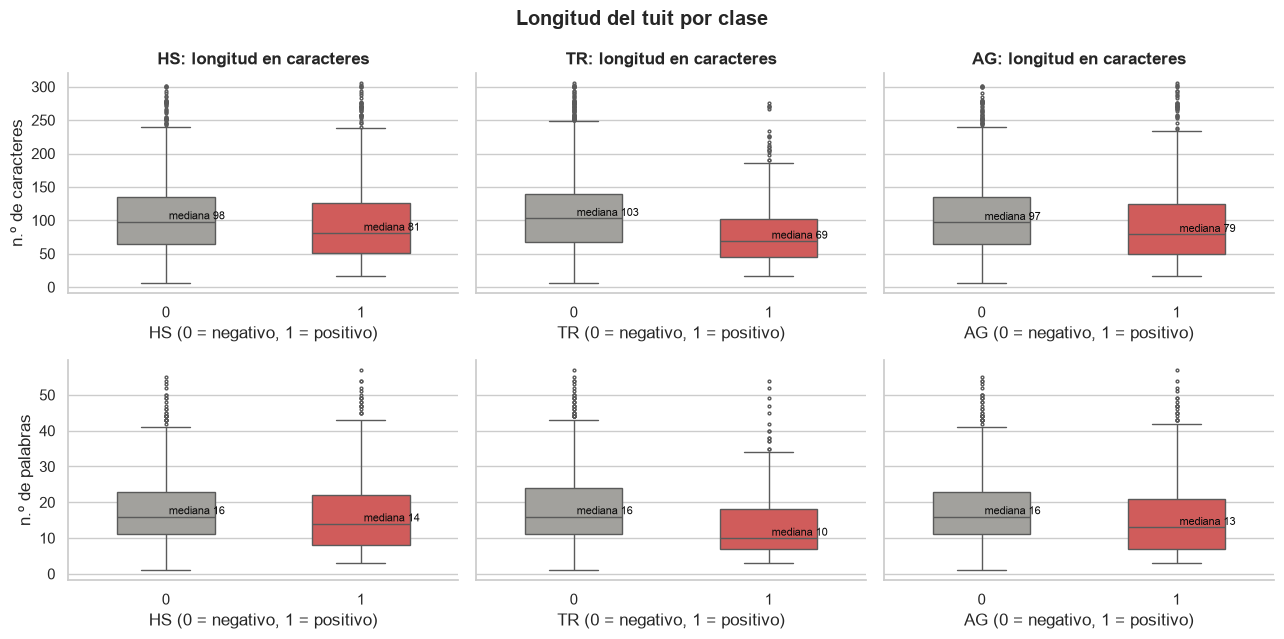

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharey="row")
for j, lab in enumerate(LABELS):
    for i, (col, name) in enumerate([("n_chars", "caracteres"), ("n_words", "palabras")]):
        ax = axes[i, j]
        sns.boxplot(data=train_feat, x=lab, y=col, hue=lab, palette=CLASS_COLORS, legend=False,
                    width=0.5, fliersize=2, ax=ax)
        med = train_feat.groupby(lab)[col].median()
        ax.set(title=f"{lab}: longitud en {name}" if i == 0 else "", xlabel=f"{lab} (0 = negativo, 1 = positivo)",
               ylabel=f"n.º de {name}" if j == 0 else "")
        for k, v in med.items():
            ax.text(k, v, f" mediana {v:.0f}", va="bottom", ha="left", fontsize=8, color="#0b0b0b")
fig.suptitle("Longitud del tuit por clase", fontweight="bold")
fig.tight_layout()
savefig(fig, "length_by_label")
plt.show()

**Interpretación:** Los tuits positivos son **más cortos**, sobre todo en TR: mediana de 69 caracteres y 10 palabras frente a 103 caracteres y 16 palabras en TR=0. En HS la diferencia es menor (81 frente a 98 caracteres) y en AG similar (79 frente a 97). La longitud aporta algo de señal, pero las distribuciones se solapan mucho.

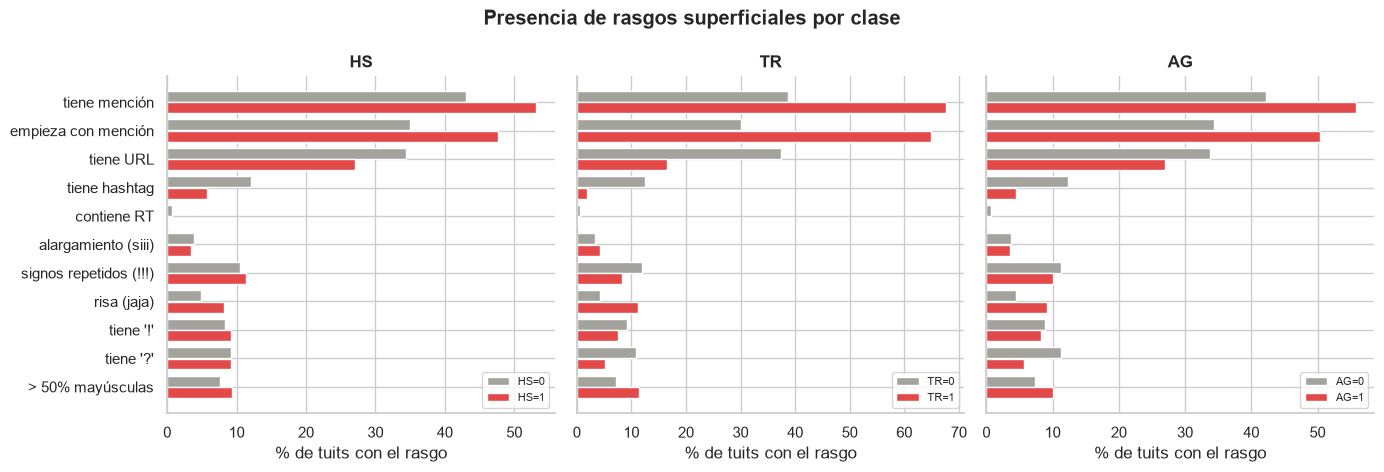

In [13]:
binary_feats = ["has_mention", "starts_mention", "has_url", "has_hashtag", "has_rt",
                "has_elong", "has_punct_rep", "has_laugh", "has_excl", "has_quest", "mostly_upper"]
feat_names = {
    "has_mention": "tiene mención", "starts_mention": "empieza con mención", "has_url": "tiene URL",
    "has_hashtag": "tiene hashtag", "has_rt": "contiene RT", "has_elong": "alargamiento (siii)",
    "has_punct_rep": "signos repetidos (!!!)", "has_laugh": "risa (jaja)", "has_excl": "tiene '!'",
    "has_quest": "tiene '?'", "mostly_upper": "> 50% mayúsculas",
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharey=True)
y = np.arange(len(binary_feats))
for ax, lab in zip(axes, LABELS):
    rates = 100 * train_feat.groupby(lab)[binary_feats].mean().T
    ax.barh(y - 0.2, rates[0], height=0.38, color=CLASS_COLORS[0], label=f"{lab}=0")
    ax.barh(y + 0.2, rates[1], height=0.38, color=CLASS_COLORS[1], label=f"{lab}=1")
    ax.set(title=lab, xlabel="% de tuits con el rasgo", yticks=y, yticklabels=[feat_names[f] for f in binary_feats])
    ax.invert_yaxis()
    ax.legend(loc="lower right", fontsize=8)
fig.suptitle("Presencia de rasgos superficiales por clase", fontweight="bold")
fig.tight_layout()
savefig(fig, "surface_features_by_label")
plt.show()

In [14]:
# Tabla resumen: media de cada rasgo en la clase positiva vs negativa (los binarios se leen como proporción)
summary_cols = ["n_chars", "n_words", "upper_ratio", "n_excl", "n_quest", "n_mentions", "n_urls", "n_hashtags"] + binary_feats
tables = {}
for lab in LABELS:
    g = train_feat.groupby(lab)[summary_cols].mean().T
    tables[lab] = pd.DataFrame({"media 0": g[0], "media 1": g[1], "ratio 1/0": g[1] / g[0].replace(0, np.nan)})
feature_summary = pd.concat(tables, axis=1).astype(float).round(2)
display(feature_summary)

HS                        TR                        AG                  
               media 0 media 1 ratio 1/0 media 0 media 1 ratio 1/0 media 0 media 1 ratio 1/0
n_chars         108.05   99.49      0.92  114.76   79.92      0.70  108.52   97.51      0.90
n_words          17.87   16.16      0.90   18.80   13.20      0.70   18.01   15.70      0.87
upper_ratio       0.12    0.13      1.05    0.11    0.15      1.28    0.12    0.14      1.18
n_excl            0.26    0.24      0.91    0.26    0.22      0.85    0.26    0.23      0.86
n_quest           0.14    0.13      0.97    0.16    0.08      0.51    0.17    0.08      0.51
n_mentions        0.69    0.77      1.13    0.62    0.96      1.54    0.68    0.80      1.17
n_urls            0.38    0.28      0.74    0.41    0.17      0.42    0.36    0.29      0.78
n_hashtags        0.23    0.08      0.35    0.22    0.03      0.13    0.23    0.06      0.29
has_mention       0.43    0.53      1.24    0.39    0.68      1.74    0.42    0.56      1.32
starts_mention    0.35    0.48      1.36    0.30    0.65      2.16    0.34    0.50      1.46
has_url           0.34    0.27      0.78    0.37    0.17      0.44    0.34    0.27      0.80
has_hashtag       0.12    0.06      0.47    0.12    0.02      0.15    0.12    0.05      0.37
has_rt            0.01    0.00      0.18    0.01    0.00      0.33    0.01    0.00      0.23
has_elong         0.04    0.03      0.91    0.03    0.04      1.25    0.04    0.04      0.99
has_punct_rep     0.10    0.11      1.09    0.12    0.08      0.69    0.11    0.10      0.89
has_laugh         0.05    0.08      1.70    0.04    0.11      2.66    0.04    0.09      2.05
has_excl          0.08    0.09      1.10    0.09    0.08      0.82    0.09    0.08      0.93
has_quest         0.09    0.09      1.00    0.11    0.05      0.48    0.11    0.06      0.51
mostly_upper      0.08    0.09      1.24    0.07    0.11      1.60    0.07    0.10      1.39

**Interpretación:** Los rasgos superficiales separan mejor **TR**. Los tuits TR=1 empiezan con mención el doble de veces (65% frente a 30%; ratio 2.16), casi nunca llevan hashtag (2% frente a 12%; ratio 0.15), tienen menos URLs (17% frente a 37%) y menos preguntas (5% frente a 11%), y se ríen más (11% frente a 4%). El perfil típico de TR=1 es una **respuesta corta a una persona** (`@usuario cállate + insulto`), mientras que los negativos se parecen más a **titulares con enlace y hashtag**. En HS y AG van en la misma dirección pero con menos fuerza (hashtag 0.47×, URL 0.78×, empieza con mención 1.36× en HS). Los signos `!` y los alargamientos casi no cambian entre clases.

## 4. Calidad y codificación del texto

En español las tildes, la ñ, la ü y los signos de apertura (¿ ¡) son caracteres **no ASCII**. Si en algún paso de la exportación se eliminaron, palabras como *cállate* o *España* quedan como *cllate* y *espaa*. Esto importa porque:

- **fragmenta el vocabulario**: la misma palabra aparece en varias formas (*cllate* cuando se borró la tilde y *callate* cuando el usuario no la escribió);
- **afecta a los léxicos externos**, que estarán escritos con tildes y no coincidirán con el texto;
- **puede romper la coherencia entre train y test** si uno conserva las tildes y el otro no.

Primero contamos los caracteres no ASCII y los emojis; después buscamos palabras que parecen haber perdido letras.

In [15]:
def char_report(s: pd.Series, name: str) -> dict:
    chars = Counter(ch for text in s for ch in text if ord(ch) > 127)
    emoji = sum(n for ch, n in chars.items() if unicodedata.category(ch) == "So" or ord(ch) >= 0x1F000)
    accented = sum(n for ch, n in chars.items() if ch.lower() in "áéíóúüñ")
    return {
        "conjunto": name,
        "tuits": len(s),
        "caracteres totales": int(s.str.len().sum()),
        "caracteres no ASCII": sum(chars.values()),
        "tuits con no ASCII": int(s.map(lambda t: any(ord(c) > 127 for c in t)).sum()),
        "tildes/ñ/ü": accented,
        "¿ ¡": chars["¿"] + chars["¡"],
        "emojis": emoji,
        "detalle": dict(chars.most_common(10)),
    }


reports = [char_report(train["text"], "train")]
if HAS_TEST:
    reports.append(char_report(test["text"], "test"))
display(pd.DataFrame(reports).set_index("conjunto"))

,tuits,caracteres totales,caracteres no ASCII,tuits con no ASCII,tildes/ñ/ü,¿ ¡,emojis,detalle
conjunto,,,,,,,,
train,1731,180565,0,0,0,0,0,{}
test,1154,117383,6,6,0,6,0,{'¿': 6}


**Interpretación:** El train tiene **0 caracteres no ASCII** en 180 565 caracteres: ni una tilde, ñ, ü, ¿, ¡ ni emoji. En el test solo hay 6, todos el `¿` de las celdas `#¿NOMBRE?`, que viene de Excel y no de los tuits. **El texto real del test tampoco trae tildes, ñ ni emojis.** Como los emojis también son caracteres no ASCII, lo más probable es que el mismo proceso los eliminara, así que no hay señal de emojis disponible.

### ¿Se borraron las tildes o los usuarios no las escribieron?

Ambas cosas pasan en Twitter, así que hay que distinguirlas. Para una lista de palabras frecuentes con caracteres no ASCII contamos tres formas:

- **correcta** (*cállate*): debería aparecer si el texto conservara la codificación;
- **borrada** (*cllate*): el carácter no ASCII desaparece; solo puede venir de un fallo de codificación;
- **sin tilde** (*callate*): el usuario escribió sin tilde, algo habitual en Twitter.

Si la forma correcta nunca aparece y la borrada es frecuente, la pérdida es **sistemática** (ocurrió al exportar los datos) y no se debe al estilo de los usuarios.

In [16]:
# Palabra correcta -> (forma con el carácter no ASCII borrado, forma sin tilde)
ACCENT_PAIRS = {
    "cállate": ("cllate", "callate"), "españa": ("espaa", "espana"), "más": ("ms", "mas"),
    "también": ("tambin", "tambien"), "año": ("ao", "ano"), "años": ("aos", "anos"),
    "niño": ("nio", "nino"), "país": ("pas", "pais"), "árabe": ("rabe", "arabe"),
    "árabes": ("rabes", "arabes"), "inmigración": ("inmigracin", "inmigracion"),
    "violación": ("violacin", "violacion"), "enseñar": ("ensear", "ensenar"), "coño": ("coo", "cono"),
    "señor": ("seor", "senor"), "güero": ("gero", "guero"), "aquí": ("aqu", "aqui"), "así": ("as", "asi"),
    "después": ("despus", "despues"), "imbécil": ("imbcil", "imbecil"), "estúpida": ("estpida", "estupida"),
    "maricón": ("maricn", "maricon"), "cabrón": ("cabrn", "cabron"), "mamá": ("mam", "mama"),
    "está": ("est", "esta"), "qué": ("qu", "que"), "tú": ("t", "tu"),
}

def word_counts(s: pd.Series) -> Counter:
    return Counter(w for t in s.map(strip_handles).str.lower() for w in re.findall(r"[^\W\d_]+", t))

wc_train = word_counts(train["text"])
wc_test = word_counts(test["text"]) if HAS_TEST else Counter()

rows = []
for correct, (deleted, plain) in ACCENT_PAIRS.items():
    row = {"palabra": correct, "borrada": deleted, "sin tilde": plain,
           "train: correcta": wc_train[correct], "train: borrada": wc_train[deleted], "train: sin tilde": wc_train[plain]}
    if HAS_TEST:
        row.update({"test: correcta": wc_test[correct], "test: borrada": wc_test[deleted], "test: sin tilde": wc_test[plain]})
    rows.append(row)
accent_table = pd.DataFrame(rows).sort_values("train: borrada", ascending=False)
display(accent_table)
print("Nota: 'que', 'tu', 'esta', 'mas', 'as' y 't' también son palabras válidas por sí mismas;"
      " su columna 'sin tilde' mezcla dos palabras distintas.")

,palabra,borrada,sin tilde,train: correcta,train: borrada,train: sin tilde,test: correcta,test: borrada,test: sin tilde
0,cállate,cllate,callate,0,159,212,0,120,138
26,tú,t,tu,0,97,282,0,73,142
2,más,ms,mas,0,90,41,0,63,21
8,árabe,rabe,arabe,0,65,36,0,36,36
9,árabes,rabes,arabes,0,61,19,0,32,12
25,qué,qu,que,0,50,886,0,35,623
10,inmigración,inmigracin,inmigracion,0,38,6,0,18,5
24,está,est,esta,0,37,59,0,17,43
1,españa,espaa,espana,0,37,1,0,19,0
12,enseñar,ensear,ensenar,0,36,0,0,33,0


Nota: 'que', 'tu', 'esta', 'mas', 'as' y 't' también son palabras válidas por sí mismas; su columna 'sin tilde' mezcla dos palabras distintas.


**Interpretación:** La pérdida es **sistemática y por borrado**:
- Las formas correctas (*cállate*, *España*, *más*...) aparecen **0 veces** en train y en test.
- Las formas borradas son frecuentes: *cllate* 159, *ms* 90, *rabe* 65, *inmigracin* 38, *espaa* 37, *ensear* 36.
- El carácter desaparece en lugar de sustituirse por su equivalente ASCII: *espaa* aparece 37 veces y *espana* 1; *ensear* 36 y *ensenar* 0; *gero* (güero) 31 y *guero* 0, así que también se borró la ü. Las mayúsculas acentuadas siguen el mismo patrón (*CLLATE*).

El test sigue **exactamente el mismo patrón** (*cllate* 120, *espaa* 19, 0 formas correctas), así que train y test son coherentes entre sí. El problema práctico es la **fragmentación**: la misma palabra aparece como *cllate* (159) y *callate* (212, escrita sin tilde por el usuario), o como *rabe* (65) y *arabe* (36). Para un modelo de bolsa de palabras son dos tokens distintos.

### Vocabulario truncado: palabras que parecen haber perdido letras

Sin un diccionario de referencia no podemos detectar todas las palabras dañadas, pero el borrado deja huellas reconocibles. Marcamos como **sospechoso** un token (en minúsculas, sin URLs ni menciones) que cumpla alguna de estas reglas:

1. **lista conocida**: está entre las formas borradas de la tabla anterior, excepto las ambiguas *as*, *t*, *est* y *pas*, que también son palabras o abreviaturas válidas;
2. **terminación -cin / -sin** (de *-ción / -sión*) con 5 o más letras: *inmigracin*, *agresin*;
3. **sin vocales** (2 o más letras) y fuera de una lista de abreviaturas habituales (*xq*, *hdp*, *rt*, *xd*...): *cn*;
4. **vocal doble improbable** (*aa*, *ii*, *uu*) que no es un alargamiento: *maana* (mañana).

Es una estimación **conservadora**: deja fuera las formas ambiguas y cualquier palabra dañada que no siga estos patrones (por ejemplo, *cmo* por *cómo* o *pelcula* por *película*). Aun así sirve para medir el alcance del problema.

In [17]:
AMBIGUOUS = {"as", "t", "est", "pas"}
KNOWN_DELETED = {d for d, _ in ACCENT_PAIRS.values()} - AMBIGUOUS
ABBREVIATIONS = {"rt", "xq", "pq", "q", "k", "hdp", "ctm", "lpm", "ptm", "hp", "csm", "xd", "xdd", "xddd", "mmm", "mm",
                 "jsjs", "jsjsjs", "tb", "tmb", "cc", "dm", "bb", "pls", "plz", "gt", "lt", "amp", "http", "https",
                 "cdmx", "ddhh", "fc", "tv", "pm", "sr", "mr", "dr", "fb", "pp", "psoe", "mx", "df", "km", "kg", "vs",
                 "x", "y", "d", "l", "s", "n", "m", "c", "p", "b", "v", "w", "j", "h", "g", "f", "z", "r", "nd", "nm",
                 "eeuu", "ee", "uu"}


def suspicious_reason(w: str) -> str | None:
    if w in KNOWN_DELETED:
        return "lista conocida"
    if len(w) >= 5 and re.search(r"[cs]in$", w):
        return "-cin/-sin"
    if len(w) >= 2 and not re.search(r"[aeiouy]", w) and w not in ABBREVIATIONS and not re.fullmatch(r"(js)+|(\w)\2+", w):
        return "sin vocales"
    if re.search(r"(aa|ii|uu)", w) and not RE_ELONG.search(w) and w not in ABBREVIATIONS:
        return "vocal doble"
    return None


susp = {w: suspicious_reason(w) for w in wc_train}
susp = {w: r for w, r in susp.items() if r}
susp_df = (pd.DataFrame([(w, r, wc_train[w]) for w, r in susp.items()], columns=["token", "regla", "frecuencia"])
           .sort_values("frecuencia", ascending=False).reset_index(drop=True))

tokens_per_text = train["text"].map(strip_handles).str.lower().map(lambda t: re.findall(r"[^\W\d_]+", t))
has_susp = tokens_per_text.map(lambda ws: any(w in susp for w in ws))
n_tokens = sum(wc_train.values())
n_susp_tokens = sum(wc_train[w] for w in susp)
print(f"Tipos (palabras distintas) sospechosos: {len(susp)} de {len(wc_train)} ({100 * len(susp) / len(wc_train):.1f}%)")
print(f"Ocurrencias sospechosas: {n_susp_tokens} de {n_tokens} tokens ({100 * n_susp_tokens / n_tokens:.1f}%)")
print(f"Tuits con al menos un token sospechoso: {has_susp.sum()} de {len(train)} ({100 * has_susp.mean():.1f}%)")
display(susp_df.groupby("regla")["frecuencia"].agg(tipos="size", ocurrencias="sum"))
display(susp_df.head(30))

Tipos (palabras distintas) sospechosos: 205 de 6225 (3.3%)
Ocurrencias sospechosas: 972 de 27588 tokens (3.5%)
Tuits con al menos un token sospechoso: 750 de 1731 (43.3%)


,tipos,ocurrencias
regla,,
-cin/-sin,93,141
lista conocida,22,724
sin vocales,51,59
vocal doble,39,48


,token,regla,frecuencia
0,cllate,lista conocida,159
1,ms,lista conocida,90
2,rabe,lista conocida,65
3,rabes,lista conocida,61
4,qu,lista conocida,50
5,inmigracin,lista conocida,38
6,espaa,lista conocida,37
7,ensear,lista conocida,36
8,violacin,lista conocida,34
9,gero,lista conocida,31


**Interpretación:** Con reglas conservadoras, **205 de 6225 palabras distintas (3.3%)** parecen haber perdido letras. Suman **972 de 27 588 tokens (3.5%)** y aparecen en el **43.3% de los tuits** (750). Casi todo el volumen lo concentran unas pocas palabras muy frecuentes de la lista conocida (*cllate*, *ms*, *rabe*, *rabes*, *qu*, *inmigracin*, *espaa*, *ensear*, *violacin*, *gero*). La regla *-cin/-sin* encuentra muchas palabras distintas pero con poca frecuencia cada una (*cancin*, *atencin*, *poblacin*...). Restaurar las ~20 formas más frecuentes cubriría la mayor parte del problema.

### Otros artefactos de exportación

Revisamos huellas típicas de haber pasado los datos por Excel u otra herramienta: comillas duplicadas (`""texto""`), entidades HTML (`&gt;`) y celdas convertidas en fórmulas (`#¿NOMBRE?`, el error `#NAME?` de Excel en español, que aparece cuando un texto empieza por `=`, `+` o `-`).

In [18]:
def artifact_report(s: pd.Series, name: str) -> dict:
    return {
        "conjunto": name,
        'comillas dobles duplicadas ("")': int(s.str.contains('""', regex=False).sum()),
        "entidades HTML (&gt; &amp; ...)": int(s.str.contains(r"&[a-z]+;|&#\d+;").sum()),
        "#¿NOMBRE? (fórmula de Excel)": int(s.str.contains("NOMBRE?", regex=False).sum()),
        "';' dentro del texto": int(s.str.contains(";", regex=False).sum()),
    }

art = [artifact_report(train["text"], "train")] + ([artifact_report(test["text"], "test")] if HAS_TEST else [])
display(pd.DataFrame(art).set_index("conjunto").T)
display(train.loc[train["text"].str.contains('""', regex=False), "text"].head(3).to_frame())

conjunto,train,test
"comillas dobles duplicadas ("""")",38,24
entidades HTML (&gt; &amp; ...),2,2
#¿NOMBRE? (fórmula de Excel),0,6
';' dentro del texto,12,9


,text
64,"""""T explicas el patriarcado como """"""""simios negratas"""""""" no vengas a exigir nada a las explicaciones de otras cuando se ha explicado desde hace aos https://..."
70,"""""Es bien naco decirle """"""""gabacho"""""""" a los """"""""yunaites"""""""""""""
71,"""""Una eurodiputada del BNG desea """"""""violaciones mltiples"""""""" a Casado para que entienda a los inmigrantes https://t.co/pqOHZaE0GU"""""


**Interpretación:** Además de las tildes hay otros artefactos de exportación: **comillas duplicadas** en 38 textos del train y 24 del test (`""Una nueva pelcula de """"wini pu""""...""`), entidades HTML (`&gt;`) en 2 y 2, y **6 tuits del test reducidos a `#¿NOMBRE?`**. Esas 6 filas no tienen texto y necesitarán una predicción por defecto. Las comillas duplicadas coinciden con el artefacto de AG descrito en la sección 2.

## 5. Vocabulario y n-gramas discriminativos

Queremos saber qué palabras distinguen a la clase positiva de la negativa en cada etiqueta.

**¿Por qué no basta con contar?** Las palabras más frecuentes (*que*, *de*, *la*) lo son en ambas clases y no discriminan. Tampoco sirve el cociente simple de frecuencias: una palabra que aparece 2 veces, ambas en la clase positiva, tendría un cociente infinito sin ninguna evidencia real.

**Log-odds ratio con prior informativo de Dirichlet** (Monroe, Colaresi y Quinn, 2008):
- Los *odds* de una palabra en una clase son la proporción de veces que aparece frente a las que no. El **log-odds ratio** (δ) compara esos odds entre la clase positiva y la negativa: δ > 0 indica que la palabra es más típica de la clase positiva.
- El **prior** suma a cada palabra sus frecuencias en el corpus completo como "pseudo-conteos". Esto encoge hacia 0 las estimaciones de palabras raras, que tienen poca evidencia.
- Dividimos δ por su desviación estándar aproximada para obtener un **z-score**. Un |z| > 1.96 equivale aproximadamente a un nivel de significancia del 5%.

Detalles: contamos **presencia por tuit** (cada palabra cuenta una vez por tuit, así una repetición como *puta puta puta* no domina), quitamos menciones, URLs y el token `rt`, y exigimos una **frecuencia mínima de 5 tuits**. No quitamos *stopwords*: pronombres como *tu* o *eres* pueden ser informativos para TR.

In [19]:
def tokenize(text: str) -> list[str]:
    """Minúsculas, sin URLs ni menciones; el '#' de los hashtags se descarta y se conserva la palabra."""
    words = re.findall(r"[^\W\d_]+", strip_handles(text).lower())
    return [w for w in words if w != "rt"]


def ngrams(tokens, n):
    return [" ".join(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]


train_tokens = train["text"].map(tokenize)
docs = {1: train_tokens.map(set), 2: train_tokens.map(lambda t: set(ngrams(t, 2)))}


def log_odds(doc_sets: pd.Series, y: pd.Series, min_df: int = 5) -> pd.DataFrame:
    """Log-odds ratio con prior informativo de Dirichlet (prior = frecuencias de documento del corpus completo)."""
    pos = Counter(w for s in doc_sets[y == 1] for w in s)
    neg = Counter(w for s in doc_sets[y == 0] for w in s)
    prior = pos + neg
    n_pos, n_neg, a0 = sum(pos.values()), sum(neg.values()), sum(prior.values())
    rows = []
    for w, a_w in prior.items():
        if a_w < min_df:
            continue
        yp, yn = pos[w], neg[w]
        lp = np.log((yp + a_w) / (n_pos + a0 - yp - a_w))
        ln = np.log((yn + a_w) / (n_neg + a0 - yn - a_w))
        delta = lp - ln
        z = delta / np.sqrt(1 / (yp + a_w) + 1 / (yn + a_w))
        rows.append((w, yp, yn, round(100 * yp / (yp + yn), 1), delta, z))
    return (pd.DataFrame(rows, columns=["término", "n pos", "n neg", "% pos", "delta", "z"])
            .sort_values("z", ascending=False).reset_index(drop=True))


lo_uni = {lab: log_odds(docs[1], train[lab]) for lab in LABELS}
lo_bi = {lab: log_odds(docs[2], train[lab]) for lab in LABELS}
# TR condicionado a HS=1: ¿qué distingue odio dirigido a una persona del odio dirigido a un grupo?
hs1 = train["HS"] == 1
lo_tr_hs = log_odds(docs[1][hs1], train.loc[hs1, "TR"], min_df=5)
print("Vocabulario con >= 5 tuits:", len(lo_uni["HS"]), "unigramas |", len(lo_bi["HS"]), "bigramas")

Vocabulario con >= 5 tuits: 579 unigramas | 456 bigramas


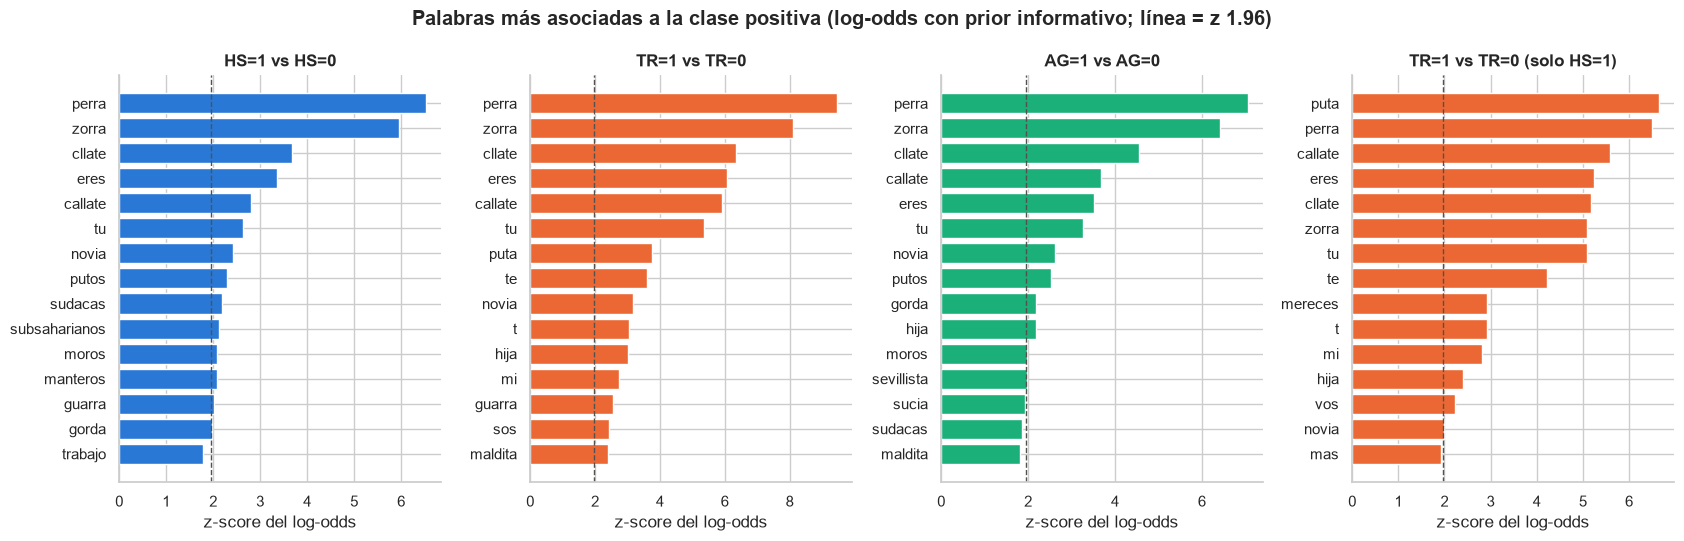

HS=1 vs HS=0: perra (z=6.5, 177/47), zorra (z=6.0, 106/13), cllate (z=3.7, 105/53), eres (z=3.4, 129/82), callate (z=2.8, 122/89)
TR=1 vs TR=0: perra (z=9.4, 174/50), zorra (z=8.1, 105/14), cllate (z=6.3, 105/53), eres (z=6.1, 124/87), callate (z=5.9, 122/89)
AG=1 vs AG=0: perra (z=7.1, 170/54), zorra (z=6.4, 103/16), cllate (z=4.6, 105/53), callate (z=3.7, 120/91), eres (z=3.5, 118/93)
TR=1 vs TR=0 (solo HS=1): puta (z=6.6, 202/10), perra (z=6.5, 174/3), callate (z=5.6, 122/0), eres (z=5.2, 124/5), cllate (z=5.2, 105/0)
(entre paréntesis: z, tuits en clase positiva / negativa)


In [20]:
TOP = 15
fig, axes = plt.subplots(1, 4, figsize=(17, 5.5))
panels = [(lo_uni["HS"], "HS=1 vs HS=0", LABEL_COLORS["HS"]),
          (lo_uni["TR"], "TR=1 vs TR=0", LABEL_COLORS["TR"]),
          (lo_uni["AG"], "AG=1 vs AG=0", LABEL_COLORS["AG"]),
          (lo_tr_hs, "TR=1 vs TR=0 (solo HS=1)", LABEL_COLORS["TR"])]
for ax, (df_lo, title, color) in zip(axes, panels):
    top = df_lo.head(TOP)
    ax.barh(top["término"], top["z"], color=color)
    ax.axvline(1.96, color="#52514e", ls="--", lw=1)
    ax.invert_yaxis()
    ax.set(title=title, xlabel="z-score del log-odds")
fig.suptitle("Palabras más asociadas a la clase positiva (log-odds con prior informativo; línea = z 1.96)", fontweight="bold")
fig.tight_layout()
savefig(fig, "log_odds_unigrams")
plt.show()

for df_lo, title, _ in panels:
    top5 = ", ".join(f"{r['término']} (z={r['z']:.1f}, {r['n pos']}/{r['n neg']})" for _, r in df_lo.head(5).iterrows())
    print(f"{title}: {top5}")
print("(entre paréntesis: z, tuits en clase positiva / negativa)")

**Interpretación:** - **HS:** dominan los insultos femeninos *perra* (z = 6.5; 177 tuits positivos frente a 47 negativos) y *zorra* (z = 6.0; 106 frente a 13), seguidos de *cllate/callate* y de la segunda persona (*eres*, *tu*). También aparecen términos sobre migrantes (*sudacas*, *subsaharianos*, *moros*, *manteros*) y otros insultos dirigidos a mujeres (*guarra*, *gorda*).
- **TR:** las mismas palabras con z más alto (*perra* 9.4, *zorra* 8.1), más pronombres de segunda persona (*tu*, *te*, *t*, *eres*, *sos*, *mi*).
- **TR dentro de HS=1:** *puta* (202 frente a 10), *perra* (174 frente a 3), *callate* (122 frente a 0) y *eres* (124 frente a 5) separan casi perfectamente el odio dirigido a una persona del dirigido a un colectivo.
- **AG** se parece mucho a HS.

Llama la atención que *puta*, la palabra más frecuente del corpus, **no** esté entre las más asociadas a HS: aparece en ambas clases. Además, *cllate* y *callate* salen como dos rasgos separados, que es la fragmentación descrita en la sección 4.

In [21]:
# Top bigramas asociados a la clase positiva y top unigramas asociados a la clase NEGATIVA (z más bajo)
bigram_table = pd.concat({lab: lo_bi[lab].head(12)[["término", "n pos", "n neg", "z"]].reset_index(drop=True)
                          for lab in LABELS}, axis=1)
bigram_table = bigram_table.round(1)
print("Bigramas más asociados a la clase positiva")
display(bigram_table)

neg_table = pd.concat({lab: lo_uni[lab].tail(10).iloc[::-1][["término", "n pos", "n neg", "z"]].reset_index(drop=True)
                       for lab in LABELS}, axis=1).round(1)
print("Unigramas más asociados a la clase NEGATIVA")
display(neg_table)

Bigramas más asociados a la clase positiva


HS                              TR                              AG                 
          término n pos n neg    z        término n pos n neg    z        término n pos n neg    z
0    cllate perra    27     0  3.5        tu eres    77    42  5.4   cllate perra    27     0  3.8
1        eres una    33     4  3.3       eres una    33     4  4.6       eres una    32     5  3.6
2    callate puta    27     2  3.2   cllate perra    27     0  4.5   callate puta    27     2  3.6
3         tu eres    78    41  3.1   callate puta    27     2  4.3        tu eres    73    46  3.4
4     cllate puta    17     1  2.6    cllate puta    17     1  3.5    cllate puta    17     1  2.9
5        novia es    21     4  2.5        eres la    22     6  3.4       novia es    20     5  2.6
6   callate perra    13     0  2.4      una perra    18     4  3.2   cllate zorra    15     2  2.5
7         eres la    22     6  2.3  callate perra    13     0  3.1      una zorra    12     1  2.4
8    cllate zorra    15     2  2.2   cllate zorra    15     2  3.1  callate perra    12     1  2.4
9       una perra    18     4  2.2       novia es    19     6  3.1  callate zorra    10     0  2.3
10      eres bien    10     0  2.1        hija de    22    10  3.1      una perra    17     5  2.3
11  callate zorra    10     0  2.1         t eres    31    23  3.0        eres la    20     8  2.2

Unigramas más asociados a la clase NEGATIVA


HS                            TR                         AG                 
    término n pos n neg    z      término n pos n neg    z   término n pos n neg    z
0      hijo     2    96 -4.5          los    19   243 -3.0      hijo     2    96 -3.8
1     acoso     6    56 -2.9         hijo     1    97 -2.6     acoso     5    57 -2.5
2      rabe     7    57 -2.8           en    57   360 -2.3      rabe     7    57 -2.2
3        de   282   542 -2.4           de   141   683 -2.1        en   110   307 -2.1
4   escoria     4    39 -2.4           el    52   313 -2.0  violacin     2    32 -2.0
5  violacin     2    32 -2.4         rabe     1    63 -2.0   escoria     4    39 -2.0
6     madre    16    68 -2.4        acoso     1    61 -2.0     polla     8    52 -2.0
7        la   220   428 -2.2  inmigrantes     1    57 -1.9        de   246   578 -1.8
8     polla    11    49 -2.1        rabes     1    57 -1.9     madre    16    68 -1.7
9        en   137   280 -2.0          son     2    63 -1.9        la   192   456 -1.7

**Interpretación:** Los bigramas confirman dos plantillas: **"cállate + insulto"** (*cllate perra* 27 frente a 0, *callate puta* 27 frente a 2) y **"(tú) eres una + insulto"** (*eres una* 33 frente a 4, *tu eres* 78 frente a 41).

En la clase negativa destacan *hijo* (2 tuits HS frente a 96 no HS; z = −4.5), *acoso* (6 frente a 56), *rabe*, *escoria* y *violacin*. Es decir, **los insultos dirigidos a hombres** (*hijo de puta*) y los **temas de noticias** (acoso, violación) suelen ser HS=0. Para TR, las palabras negativas son plurales y colectivos (*los*, *inmigrantes*, *rabes*, *son*), lo que encaja con TR=0 = odio contra un grupo.

Interpretación (hipótesis): el patrón encaja con un corpus del estilo **HatEval 2019** (SemEval-2019, tarea 5), donde HS se anota solo contra **mujeres e inmigrantes**, y TR/AG solo se evalúan cuando HS=1.

### Palabras más frecuentes en general

Como referencia, las palabras más frecuentes de todo el train, sin menciones, URLs ni *stopwords*. La lista de *stopwords* se define aquí a mano (sin librerías externas) e incluye las formas con tilde borrada (*ms*, *qu*, *est*...).

In [22]:
STOPWORDS_ES = set("""
a al algo algunos ante antes aqui aqu as asi aun aunque bien cada como con contra cual cuando de del desde donde dos
el ella ellas ellos en entre era eres es esa ese eso esos esta est estas estoy este esto estos fue ha hace han hasta hay
la las le les lo los mas ms me mi mis mucho muy nada ni no nos o otra otro para pero poco por porque pues q que qu
se sea ser si s sin sobre son su sus t tal tambien tambin te tengo ti tiene todo todos tu tus un una uno unos va vez y ya yo
""".split())

doc_freq = Counter(w for s in docs[1] for w in s)
top_overall = pd.DataFrame(
    [(w, n, round(100 * n / len(train), 1)) for w, n in doc_freq.most_common() if w not in STOPWORDS_ES][:27],
    columns=["palabra", "tuits", "% tuits"])
# Tres bloques lado a lado para que la tabla sea compacta
display(pd.concat([top_overall.iloc[i:i + 9].reset_index(drop=True) for i in (0, 9, 18)], axis=1,
                  keys=["1-9", "10-18", "19-27"]))

1-9                      10-18                         19-27              
   palabra tuits % tuits      palabra tuits % tuits         palabra tuits % tuits
0     puta   554    32.0        acoso    62     3.6      inmigracin    38     2.2
1    perra   224    12.9        polla    60     3.5           arabe    36     2.1
2  callate   211    12.2  inmigrantes    58     3.4           espaa    35     2.0
3   cllate   158     9.1       mierda    58     3.4             vos    35     2.0
4    zorra   119     6.9        rabes    58     3.4          ensear    34     2.0
5     hijo    98     5.7         cara    53     3.1            hija    34     2.0
6    madre    84     4.9        mujer    51     2.9           mejor    34     2.0
7  mereces    77     4.4         boca    43     2.5        violacin    34     2.0
8     rabe    64     3.7      escoria    43     2.5  indocumentados    33     1.9

**Interpretación:** Las palabras más frecuentes son insultos y palabras clave: *puta* (554 tuits, 32.0%), *perra* (12.9%), *callate* (12.2%), *cllate* (9.1%), *zorra* (6.9%), *hijo*, *madre*, *mereces*, *rabe*, *acoso*, *inmigrantes*... Todo indica que el corpus se **recolectó con palabras clave** (insultos frecuentes contra mujeres y términos sobre migración). Por eso la simple presencia de una palabra clave discrimina poco: aparece en ambas clases y lo que decide es el contexto.

## 5b. Análisis lingüístico con spaCy

Hasta aquí trabajamos con palabras tal como aparecen. Ahora usamos un analizador lingüístico para obtener, de cada palabra:

- su **lema**, la forma de diccionario (*eres*, *es*, *soy* → *ser*), que agrupa variantes de una misma palabra;
- su **categoría gramatical** o *POS* (*part of speech*): verbo, sustantivo, adjetivo, pronombre, interjección...;
- su **morfología**: modo (*Mood*: indicativo, subjuntivo, **imperativo**), **persona** (1.ª, 2.ª, 3.ª), número y tiempo.

**Qué está permitido y qué usamos:** las reglas permiten lematizadores y etiquetadores como spaCy, pero no los vectores preentrenados. Usamos **solo** `lemma_`, `pos_` y `morph` (Mood, Person, Number, Tense). **No** usamos `token.vector`, `doc.vector`, NER ni clasificación de texto. Además, cargamos el modelo **sin** los componentes `ner`, `parser` y `senter`.

**Modelo:** `es_core_news_sm` **3.8.0** (requiere spaCy >=3.8.0,<3.9.0), de Explosion.
- **Licencia: GNU GPL 3.0**, verificada en la página de la versión ([github.com/explosion/spacy-models/releases/tag/es_core_news_sm-3.8.0](https://github.com/explosion/spacy-models/releases/tag/es_core_news_sm-3.8.0)) y en los metadatos del paquete instalado.
- **Datos de entrenamiento:** UD Spanish AnCora v2.8 (GPL 3.0), WikiNER (CC BY 4.0) y spaCy lookups data (MIT). Es texto **periodístico**, no tuits.
- **Precisión publicada** (sobre AnCora): POS 98.13%, morfología 97.72%, lema 96.31%.
- El modelo **no trae vectores de palabras** (0 claves, 0 dimensiones). Su componente `tok2vec` es una capa interna del etiquetador; no extraemos de ella ninguna representación.
- Instalación reproducible: `uv add "es_core_news_sm @ <URL del wheel 3.8.0>"` (queda fijado en `pyproject.toml`).

In [23]:
import time

import spacy

spacy.util.fix_random_seed(SEED)
SPACY_MODEL = "es_core_news_sm"
nlp = spacy.load(SPACY_MODEL, exclude=["ner", "parser", "senter"])  # solo etiquetado morfológico y lematización

meta = nlp.meta
print(f"spaCy {spacy.__version__} | modelo {meta['lang']}_{meta['name']} {meta['version']} | licencia: {meta['license']}")
print("Fuentes:", [(s["name"], s["license"]) for s in meta["sources"]])
print("Componentes activos:", nlp.pipe_names)
print("Vectores del modelo (filas, dimensiones):", nlp.vocab.vectors.shape)
assert nlp.vocab.vectors.shape[0] == 0, "El modelo no debe traer vectores preentrenados"

spaCy 3.8.16 | modelo es_core_news_sm 3.8.0 | licencia: GNU GPL 3.0
Fuentes: [('UD Spanish AnCora v2.8', 'GNU GPL 3.0'), ('WikiNER', 'CC BY 4.0'), ('spaCy lookups data', 'MIT')]
Componentes activos: ['tok2vec', 'morphologizer', 'attribute_ruler', 'lemmatizer']
Vectores del modelo (filas, dimensiones): (0, 0)


### Preparación del texto y tiempo de proceso

Antes de pasar los tuits a spaCy les aplicamos una limpieza mínima: quitamos URLs, menciones, comillas y el símbolo `#`, porque no son lenguaje y confunden al etiquetador. Procesamos dos versiones:

- **original:** conserva las mayúsculas;
- **minúsculas:** todo en minúsculas.

El modelo se entrenó con noticias bien escritas, así que en tuits tiende a tomar cualquier palabra con mayúscula (*Callate*, *Tu*, *CLLATE*) por un nombre propio (`PROPN`). Comparamos ambas versiones y medimos cuánto tarda.

In [24]:
def spacy_prep(text: str) -> str:
    """Limpieza mínima previa a spaCy: sin URLs, menciones, comillas ni '#'."""
    t = strip_handles(text).replace('"', " ").replace("#", " ")
    return re.sub(r"\s+", " ", t).strip()


def run_spacy(texts: pd.Series):
    start = time.perf_counter()
    docs = list(nlp.pipe(texts, batch_size=64))
    return docs, time.perf_counter() - start


def doc_table(docs) -> pd.DataFrame:
    """Una fila por token con SOLO lema, POS y morfología (sin vectores)."""
    rows = []
    for i, d in enumerate(docs):
        for t in d:
            if t.is_space:
                continue
            m = t.morph
            rows.append((i, t.text, t.lower_, t.lemma_.lower(), t.pos_, "|".join(m.get("Mood")),
                         "|".join(m.get("Person")), "|".join(m.get("Number")), "|".join(m.get("Tense")), t.is_alpha))
    return pd.DataFrame(rows, columns=["doc", "token", "lower", "lemma", "pos", "mood", "person", "number", "tense", "is_alpha"])


spacy_text = train["text"].map(spacy_prep)
docs_orig, t_orig = run_spacy(spacy_text)
docs_low, t_low = run_spacy(spacy_text.str.lower())
tok_orig, tok = doc_table(docs_orig), doc_table(docs_low)  # 'tok' (minúsculas) es la versión principal

n_tok = int(tok["is_alpha"].sum())
print(f"Train: {len(train)} tuits, {n_tok} tokens alfabéticos")
print(f"Tiempo spaCy (original):   {t_orig:.2f} s  ({1000 * t_orig / len(train):.2f} ms/tuit)")
print(f"Tiempo spaCy (minúsculas): {t_low:.2f} s  ({1000 * t_low / len(train):.2f} ms/tuit)")

pos_cmp = pd.DataFrame({
    "original": tok_orig[tok_orig.is_alpha]["pos"].value_counts(normalize=True),
    "minúsculas": tok[tok.is_alpha]["pos"].value_counts(normalize=True),
}).mul(100).round(1).loc[["PROPN", "NOUN", "VERB", "AUX", "ADJ", "PRON", "DET", "INTJ"]]
display(pos_cmp.rename_axis("POS (% de tokens)"))

Train: 1731 tuits, 27353 tokens alfabéticos
Tiempo spaCy (original):   1.57 s  (0.91 ms/tuit)
Tiempo spaCy (minúsculas): 1.32 s  (0.76 ms/tuit)


,original,minúsculas
POS (% de tokens),,
PROPN,13.5,5.3
NOUN,19.0,22.9
VERB,12.1,13.4
AUX,4.1,4.2
ADJ,7.1,8.6
PRON,7.7,8.1
DET,12.1,12.5
INTJ,0.1,0.1


**Interpretación:** Procesar el train completo tarda **≈1.5 s (menos de 1 ms por tuit)** con los cuatro componentes activos. El coste es despreciable. Además, spaCy no aprende de nuestras etiquetas: su salida es determinista, así que **se calcula una sola vez y se guarda en caché**. No hace falta repetirlo en cada fold de la validación cruzada y no filtra información entre folds.

Pasar a minúsculas reduce los falsos nombres propios del **13.5% al 5.3%** de los tokens, y a cambio suben los sustantivos (19.0 → 22.9%) y los verbos (12.1 → 13.4%). En tuits conviene **pasar a minúsculas antes de spaCy**. A partir de aquí usamos esa versión.

### 1. Proporción de categorías gramaticales por etiqueta

Para cada etiqueta calculamos qué porcentaje de los tokens de la clase positiva y de la negativa son verbos (incluidos auxiliares como *ser* o *haber*), sustantivos, nombres propios, adjetivos, pronombres e interjecciones. Si el odio dirigido a una persona es más "conversacional", esperaríamos más verbos y pronombres; los titulares deberían tener más sustantivos y nombres propios.

HS          TR          AG      
HS                0     1     0     1     0     1
% de tokens                                      
verbo          17.5  17.9  17.5  18.4  17.6  17.8
sustantivo     23.3  22.4  23.2  22.1  23.2  22.4
nombre propio   5.1   5.5   4.7   7.2   4.8   6.1
adjetivo        8.4   8.8   8.3   9.6   8.2   9.3
pronombre       7.8   8.6   7.8   9.2   8.0   8.5
interjección    0.1   0.1   0.1   0.2   0.1   0.1

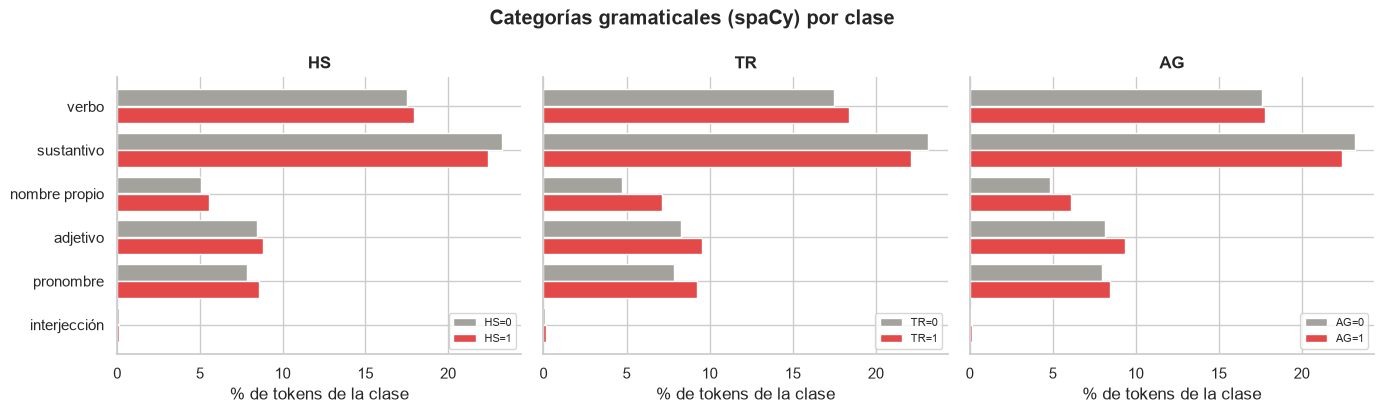

In [25]:
POS_GROUPS = {"VERB": "verbo", "AUX": "verbo", "NOUN": "sustantivo", "PROPN": "nombre propio",
              "ADJ": "adjetivo", "PRON": "pronombre", "INTJ": "interjección"}
POS_ORDER = ["verbo", "sustantivo", "nombre propio", "adjetivo", "pronombre", "interjección"]

alpha = tok[tok["is_alpha"]].copy()
alpha["pos_group"] = alpha["pos"].map(POS_GROUPS).fillna("otros")
alpha = alpha.join(train[LABELS], on="doc")

pos_share = {}
for lab in LABELS:
    share = 100 * pd.crosstab(alpha["pos_group"], alpha[lab], normalize="columns")
    pos_share[lab] = share.loc[POS_ORDER]
pos_table = pd.concat({lab: pos_share[lab].rename(columns={0: "0", 1: "1"}) for lab in LABELS}, axis=1).round(1)
display(pos_table.rename_axis("% de tokens"))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
y = np.arange(len(POS_ORDER))
for ax, lab in zip(axes, LABELS):
    s = pos_share[lab]
    ax.barh(y - 0.2, s[0], height=0.38, color=CLASS_COLORS[0], label=f"{lab}=0")
    ax.barh(y + 0.2, s[1], height=0.38, color=CLASS_COLORS[1], label=f"{lab}=1")
    ax.set(title=lab, xlabel="% de tokens de la clase", yticks=y, yticklabels=POS_ORDER)
    ax.invert_yaxis()
    ax.legend(loc="lower right", fontsize=8)
fig.suptitle("Categorías gramaticales (spaCy) por clase", fontweight="bold")
fig.tight_layout()
savefig(fig, "pos_by_label")
plt.show()

**Interpretación:** Las diferencias son **pequeñas**: ninguna categoría cambia más de 2.5 puntos.
- TR es donde más se nota: más nombres propios (7.2% frente a 4.7%; muchos son insultos mal etiquetados, como *perra* → `PROPN`), más pronombres (9.2% frente a 7.8%) y más adjetivos (9.6% frente a 8.3%). Los verbos apenas cambian (18.4% frente a 17.5%).
- Las interjecciones casi no aparecen (0.1–0.2%), porque el modelo no reconoce *jaja* como interjección.

Como rasgo agregado, la proporción de cada categoría aporta poca señal.

### 2. Imperativos y segunda persona

**Hipótesis:** las órdenes (*cállate*, *vete*) y la segunda persona (*tú eres*, *te*) deberían ser más frecuentes en TR y AG, porque esos tuits se dirigen a alguien.

La medimos de dos formas:

- **con spaCy:** el tuit tiene algún token con `Mood=Imp` (imperativo) o con `Person=2` (segunda persona);
- **con una lista léxica** definida a mano, que sirve como referencia y para comprobar si spaCy acierta:
  - imperativos frecuentes del corpus, con sus variantes sin tilde o con la tilde borrada (*callate*, *cllate*, *vete*, *comemela*, *muerete*...);
  - formas de segunda persona: *tu*, *t* (= tú con la tilde borrada), *te*, *ti*, *eres*, *sos*, *vos*, *tus*, *contigo*.

In [26]:
IMPERATIVE_FORMS = {
    "callate", "cllate", "callte", "calla", "callense", "callaos", "vete", "andate", "ndate", "largate", "lrgate",
    "muerete", "murete", "metete", "mtete", "jodete", "jdete", "matate", "mtate", "comemela", "chupamela",
    "chupala", "chpala", "fijate", "fjate", "sacate", "scate", "ponte", "dame",
}
SECOND_PERSON_FORMS = {"tu", "t", "te", "ti", "eres", "sos", "vos", "tus", "contigo"}

flags = pd.DataFrame({
    "imperativo (spaCy)": tok.groupby("doc")["mood"].apply(lambda s: s.str.contains("Imp").any()),
    "imperativo (léxico)": tok.groupby("doc")["lower"].apply(lambda s: s.isin(IMPERATIVE_FORMS).any()),
    "2.ª persona (spaCy)": tok.groupby("doc")["person"].apply(lambda s: s.str.contains("2").any()),
    "2.ª persona (léxico)": tok.groupby("doc")["lower"].apply(lambda s: s.isin(SECOND_PERSON_FORMS).any()),
}).reindex(range(len(train)), fill_value=False)

rows = {}
for lab in LABELS:
    g = flags.groupby(train[lab].values).mean().T * 100
    rows[(lab, "% en 0")] = g[0]
    rows[(lab, "% en 1")] = g[1]
    rows[(lab, "ratio 1/0")] = g[1] / g[0]
imp_table = pd.DataFrame(rows).round(2)
imp_table.insert(0, "% del train", (100 * flags.mean()).round(1))
display(imp_table)

# ¿Qué marca spaCy como imperativo y cómo etiqueta las formas de 'cállate'?
print("Tokens con Mood=Imp según spaCy:", tok.loc[tok["mood"].str.contains("Imp"), "lower"].value_counts().head(12).to_dict())
callate_tags = (tok[tok["lower"].isin(["callate", "cllate"])]
                .groupby(["lower", "lemma", "pos", "mood"]).size().sort_values(ascending=False).head(8))
display(callate_tags.to_frame("n"))

% del train     HS                      TR                      AG                 
                                 % en 0 % en 1 ratio 1/0 % en 0 % en 1 ratio 1/0 % en 0 % en 1 ratio 1/0
imperativo (spaCy)           2.9   3.08   2.65      0.86   3.05   2.50      0.82   3.18   2.42      0.76
imperativo (léxico)         23.2  16.92  31.22      1.84  13.70  45.28      3.31  15.62  35.35      2.26
2.ª persona (spaCy)         35.4  31.79  39.95      1.26  28.63  51.06      1.78  31.24  41.99      1.34
2.ª persona (léxico)        33.2  27.90  39.95      1.43  24.67  52.99      2.15  27.50  42.30      1.54

Tokens con Mood=Imp según spaCy: {'mira': 12, 'callate': 9, 'vaya': 5, 'vean': 2, 'apoyas': 2, 'ten': 1, 'inmigracin': 1, 'afirmo': 1, 'sigan': 1, 'pablotrump': 1, 'sacate': 1, 'quilombo': 1}


n
lower   lemma    pos   mood     
callate callate  NOUN        141
cllate  cllate   NOUN         80
callate callatar VERB  Sub    32
cllate  cllate   PROPN        32
                 VERB  Ind    30
callate callate  PROPN        22
cllate  cllatar  VERB  Sub    11
callate callate  VERB  Ind     7

**Interpretación:** La hipótesis **se confirma con la lista léxica, pero spaCy no sirve para medirla**.
- **Léxico:** hay imperativos en el 23.2% de los tuits. En TR=1 aparecen en el **45.3%, frente al 13.7%** de TR=0 (×3.3). En AG la proporción es 35.4% frente a 15.6% (×2.3) y en HS 31.2% frente a 16.9% (×1.8). La segunda persona sigue el mismo patrón: TR 53.0% frente a 24.7% (×2.15), AG ×1.54, HS ×1.43.
- **spaCy (`Mood=Imp`):** solo marca imperativo en el 2.9% de los tuits, y en las clases positivas la tasa es incluso *menor* (ratio 0.76–0.86). Falla con *callate/cllate*: de 370 apariciones, etiqueta 221 como sustantivo y otras como nombre propio o como verbo en indicativo o subjuntivo, con el lema inventado *callatar*. Casi nunca lo marca como imperativo. Lo que sí marca como imperativo son sobre todo *mira* y *vaya*.
- **spaCy (`Person=2`):** sí funciona razonablemente (TR 51.1% frente a 28.6%, ×1.78), con valores parecidos a los del léxico, porque *te*, *tu* y *eres* son formas frecuentes y regulares.

Conclusión: el rasgo de imperativo hay que construirlo **con reglas o léxico**, no con la morfología de spaCy. Hay que tener en cuenta que el imperativo léxico lo dominan *callate* y *cllate*, que ya son unigramas muy fuertes, así que su aporte sobre la bolsa de palabras es sobre todo **unificar variantes**.

### 3. Lemas erróneos por la pérdida de tildes y ñ

El lematizador de spaCy combina un diccionario con reglas que dependen de la categoría gramatical. Si una palabra perdió una letra (*cllate*, *espaa*) no está en el diccionario y el lema sale mal: o se queda igual que la palabra dañada o se inventa un verbo (*rabe* → *rabir*). Medimos:

1. cuántos tokens tienen una forma **dañada** según las reglas de la sección 4 (su lema no puede ser correcto);
2. ejemplos concretos de palabras frecuentes con sus lemas y POS asignados;
3. la **inestabilidad** del lema: cuántos tokens pertenecen a palabras que reciben más de un lema distinto en el corpus (*perra* → *perra*, *perrar*, *perrir*).

In [27]:
alpha_tok = tok[tok["is_alpha"]]
damaged = alpha_tok["lower"].isin(susp)
print(f"Tokens con forma dañada (reglas de la sección 4): {damaged.sum()} de {len(alpha_tok)} ({100 * damaged.mean():.1f}%)")
print(f"  ...de ellos, el lema coincide con la forma dañada: {(alpha_tok.loc[damaged, 'lemma'] == alpha_tok.loc[damaged, 'lower']).sum()}")
print(f"  ...de ellos, se inventa un verbo (-ar/-er/-ir): {alpha_tok.loc[damaged, 'lemma'].str.contains(r'(?:ar|er|ir)$').sum()}")

# Inestabilidad: palabras (forma en minúsculas) que reciben más de un lema
n_lemmas = alpha_tok.groupby("lower")["lemma"].nunique()
unstable_words = n_lemmas[n_lemmas > 1].index
unstable = alpha_tok["lower"].isin(unstable_words)
print(f"Palabras distintas con más de un lema: {len(unstable_words)} de {len(n_lemmas)}; "
      f"cubren {100 * unstable.mean():.1f}% de los tokens")

EXAMPLES = ["cllate", "callate", "perra", "zorra", "puta", "rabe", "espaa", "inmigracin", "ms", "t", "vete", "eres", "ensear"]


def lemma_profile(w):
    sub = alpha_tok[alpha_tok["lower"] == w]
    top = sub.groupby(["lemma", "pos"]).size().sort_values(ascending=False).head(4)
    return {"palabra": w, "tokens": len(sub), "lemas distintos": sub["lemma"].nunique(),
            "(lema, POS) más frecuentes": ", ".join(f"{l}/{p} ({n})" for (l, p), n in top.items())}


display(pd.DataFrame([lemma_profile(w) for w in EXAMPLES]).set_index("palabra"))

Tokens con forma dañada (reglas de la sección 4): 964 de 27353 (3.5%)
  ...de ellos, el lema coincide con la forma dañada: 875
  ...de ellos, se inventa un verbo (-ar/-er/-ir): 74
Palabras distintas con más de un lema: 301 de 6148; cubren 23.6% de los tokens


,tokens,lemas distintos,"(lema, POS) más frecuentes"
palabra,,,
cllate,158,2,"cllate/NOUN (80), cllate/PROPN (32), cllate/VERB (30), cllatar/VERB (11)"
callate,212,3,"callate/NOUN (141), callatar/VERB (32), callate/PROPN (22), callate/VERB (11)"
perra,231,3,"perra/NOUN (123), perra/PROPN (94), perra/ADJ (6), perrar/VERB (6)"
zorra,120,3,"zorra/NOUN (59), zorra/ADJ (44), zorra/PROPN (13), zorrar/VERB (3)"
puta,588,3,"puta/NOUN (532), puto/ADJ (49), putar/VERB (6), puta/PROPN (1)"
rabe,65,3,"rabe/PROPN (27), rabir/VERB (20), rabe/NOUN (14), rabe/ADJ (2)"
espaa,37,1,"espaa/NOUN (31), espaa/ADJ (6)"
inmigracin,38,2,"inmigracin/PROPN (21), inmigracin/NOUN (12), inmigracin/VERB (4), inmigracinir/VERB (1)"
ms,90,1,"ms/ADP (80), ms/NOUN (10)"


**Interpretación:** - **964 tokens (3.5%)** tienen una forma dañada. En 875 de ellos el lema es la misma forma dañada, es decir, no se lematizan. En 74 spaCy **se inventa un verbo**: *rabe* → *rabir* (20 veces), *cllate* → *cllatar*, *inmigracin* → *inmigracinir*.
- La inestabilidad también afecta a palabras sin daño: **301 palabras reciben más de un lema** y suman el **23.6% de los tokens**. Ejemplos:
  - *perra* → *perra* (NOUN 123, PROPN 94) y *perrar* (VERB 6);
  - *puta* → *puta* (NOUN 532) y *puto* (ADJ 49);
  - *zorra* → *zorrar*;
  - *vete* → *vetir* (7 de 8);
  - *t* (tú) → `CCONJ` (82 de 91);
  - *ms* (más) → `ADP`.
- *eres* → *ser* sí funciona (196 de 223).

Lemas claramente erróneos: *cllatar*, *callatar*, *perrar*, *zorrar*, *rabir*, *vetir*, *inmigracinir*.

### ¿Ayuda normalizar antes de lematizar?

Para decidir el orden de los pasos en `02_preprocesamiento`, repetimos el análisis tras **restaurar las formas dañadas más frecuentes** con el diccionario de la sección 4 (*cllate* → *cállate*, *espaa* → *españa*, *rabe* → *árabe*...). No restauramos las formas ambiguas (*as*, *t*, *est*, *pas*). Lo comparamos con el texto original y con la versión en minúsculas.

In [28]:
RESTORE = {deleted: correct for correct, (deleted, _) in ACCENT_PAIRS.items() if deleted not in AMBIGUOUS}
RESTORE["callate"] = "cállate"  # también la forma escrita sin tilde por el usuario


def restore_accents(text: str) -> str:
    return re.sub(r"[^\W\d_]+", lambda m: RESTORE.get(m.group(0), m.group(0)), text)


docs_rest, t_rest = run_spacy(spacy_text.str.lower().map(restore_accents))
tok_rest = doc_table(docs_rest)


def pipeline_metrics(t: pd.DataFrame) -> dict:
    a = t[t["is_alpha"]]
    call = a[a["lower"].isin(["callate", "cllate", "cállate"])]
    return {
        "% PROPN": round(100 * (a["pos"] == "PROPN").mean(), 1),
        "% VERB+AUX": round(100 * a["pos"].isin(["VERB", "AUX"]).mean(), 1),
        "% tokens dañados": round(100 * a["lower"].isin(susp).mean(), 1),
        "tuits con Mood=Imp": int(t.groupby("doc")["mood"].apply(lambda s: s.str.contains("Imp").any()).sum()),
        "tuits con Person=2": int(t.groupby("doc")["person"].apply(lambda s: s.str.contains("2").any()).sum()),
        "'cállate' como VERB (%)": round(100 * (call["pos"] == "VERB").mean(), 1),
        "'cállate' con Mood=Imp (%)": round(100 * call["mood"].str.contains("Imp").mean(), 1),
        "lema más frecuente de 'cállate'": call["lemma"].value_counts().index[0],
    }


norm_cmp = pd.DataFrame({"original": pipeline_metrics(tok_orig), "minúsculas": pipeline_metrics(tok),
                         "minúsculas + restauración": pipeline_metrics(tok_rest)})
display(norm_cmp)

,original,minúsculas,minúsculas + restauración
% PROPN,13.5,5.3,4.8
% VERB+AUX,16.1,17.7,18.3
% tokens dañados,3.5,3.5,0.9
tuits con Mood=Imp,38,50,48
tuits con Person=2,532,612,610
'cállate' como VERB (%),11.6,24.3,84.9
'cállate' con Mood=Imp (%),1.4,2.4,2.2
lema más frecuente de 'cállate',callate,callate,cállatir


**Interpretación:** Restaurar las formas dañadas antes de spaCy tiene efectos mixtos:
- reduce los tokens dañados del **3.5% al 0.9%**;
- hace que *cállate* se reconozca como verbo en el **84.9%** de los casos (24.3% sin restaurar);
- **no** arregla el imperativo (2.2%), y el lema sigue mal (*cállatir*). El modelo se entrenó con noticias y no maneja bien los imperativos con pronombre pegado (*cállate*, *vete*).

El paso con más efecto sobre las categorías gramaticales es pasar a minúsculas (PROPN 13.5% → 5.3% → 4.8%).

Conclusión: **normalizar antes de lematizar** (minúsculas y restauración de las formas frecuentes) mejora las categorías y reduce los tokens dañados. Aun así, los lemas de imperativos con pronombre pegado hay que **corregirlos después** con un diccionario propio.

### 4. Lemas discriminativos frente a palabras

Repetimos el **log-odds ratio con prior informativo** de la sección 5 (presencia por tuit, frecuencia mínima de 5 tuits), ahora sobre **lemas** (versión en minúsculas, sin restaurar). Lematizar agrupa formas (*eres*, *es*, *son* → *ser*). Esto puede concentrar la evidencia de varias palabras en un solo rasgo o, por el contrario, diluir diferencias útiles: por ejemplo, *eres* (2.ª persona) es muy indicativo de TR y *son* (3.ª plural) de lo contrario.

In [29]:
lemma_docs = alpha_tok[alpha_tok["lemma"] != "rt"].groupby("doc")["lemma"].apply(set).reindex(range(len(train)))
lemma_docs = lemma_docs.map(lambda s: s if isinstance(s, set) else set())

lo_lemma = {lab: log_odds(lemma_docs, train[lab]) for lab in LABELS}
n_word_types = len({w for s in docs[1] for w in s})
n_lemma_types = len({w for s in lemma_docs for w in s})
print(f"Tipos distintos: palabras {n_word_types} -> lemas {n_lemma_types} ({100 * (1 - n_lemma_types / n_word_types):.1f}% menos)")
print(f"Tipos con >= 5 tuits: palabras {len(lo_uni['HS'])} -> lemas {len(lo_lemma['HS'])}")

TOPN = 12
compare = pd.concat({
    (lab, kind): df_lo.head(TOPN).apply(lambda r: f"{r['término']} ({r['z']:.1f})", axis=1).reset_index(drop=True)
    for lab in LABELS for kind, df_lo in [("palabras", lo_uni[lab]), ("lemas", lo_lemma[lab])]
}, axis=1)
print("Top términos asociados a la clase positiva (z entre paréntesis)")
display(compare)

# Lemas que agrupan varias formas y están entre los más discriminativos
top_lemmas = set().union(*[set(lo_lemma[lab].head(25)["término"]) for lab in LABELS])
forms = (alpha_tok[alpha_tok["lemma"].isin(top_lemmas)].groupby("lemma")["lower"]
         .agg(lambda s: ", ".join(f"{w} ({n})" for w, n in s.value_counts().head(5).items())))
n_forms = alpha_tok[alpha_tok["lemma"].isin(top_lemmas)].groupby("lemma")["lower"].nunique()
display(forms[n_forms > 1].to_frame("formas agrupadas (n)"))

Tipos distintos: palabras 6224 -> lemas 5323 (14.5% menos)
Tipos con >= 5 tuits: palabras 579 -> lemas 535
Top términos asociados a la clase positiva (z entre paréntesis)


HS                                 TR                               AG                  
               palabras               lemas       palabras          lemas          palabras             lemas
0           perra (6.5)         perra (6.3)    perra (9.4)    perra (9.1)       perra (7.1)       perra (6.8)
1           zorra (6.0)         zorra (5.9)    zorra (8.1)    zorra (8.0)       zorra (6.4)       zorra (6.3)
2          cllate (3.7)        cllate (3.9)   cllate (6.3)   cllate (6.4)      cllate (4.6)      cllate (4.7)
3            eres (3.4)       callate (2.9)     eres (6.1)  callate (5.7)     callate (3.7)     callate (3.7)
4         callate (2.8)          puto (2.7)  callate (5.9)       tu (5.2)        eres (3.5)          tu (3.1)
5              tu (2.6)           ser (2.7)       tu (5.4)       tú (3.2)          tu (3.3)        puto (3.1)
6           novia (2.4)            tu (2.6)     puta (3.8)    novia (3.1)       novia (2.6)       novia (2.6)
7           putos (2.3)  subsahariano (2.6)       te (3.6)      ser (3.0)       putos (2.5)  moromierda (2.1)
8         sudacas (2.2)         novia (2.4)    novia (3.2)     puto (2.9)       gorda (2.2)         ser (2.1)
9   subsaharianos (2.1)        sudaca (2.2)        t (3.1)        t (2.9)        hija (2.2)  sevillista (2.0)
10          moros (2.1)       mantero (2.1)     hija (3.0)       mi (2.7)       moros (2.0)      guarra (1.9)
11       manteros (2.1)        ilegal (2.0)       mi (2.7)     puta (2.7)  sevillista (2.0)      perrar (1.8)

,formas agrupadas (n)
lemma,
asqueroso,"asquerosa (6), asquerosos (2), asqueroso (2)"
gordo,"gorda (7), gordo (3)"
guarra,"guarra (28), guarras (1)"
hija,"hija (30), hijas (1)"
ilegal,"ilegal (17), ilegales (12)"
merecer,"mereces (54), mereca (5), merezca (3), merece (2), merecer (1)"
mi,"mi (185), mis (16)"
moro,"moros (10), moro (1)"
moromierda,"moromierdas (6), moromierda (2)"


**Interpretación:** Lematizar reduce el vocabulario un **14.5%** (6224 → 5323 tipos; 579 → 535 con al menos 5 tuits).
- **Lo que no cambia:** los términos más discriminativos son casi los mismos (*perra*, *zorra*, *cllate*, *callate*) y con z parecidos.
- **Lo que gana:** algunos lemas suben al agrupar formas: *subsahariano* (2.6), *ilegal* (2.0) y *mantero* (2.1) entran en el top de HS.
- **Lo que pierde:**
  - *eres* (z = 3.4 en HS y 6.1 en TR) se diluye en *ser* (2.7 y 3.0) al mezclarse con *es*, *son* y *soy*. Así se pierde la señal de segunda persona, clave para TR.
  - *te* se agrupa con *os* (vosotros) y *ti* bajo el lema *tú*.
  - Aparece un lema erróneo, *perrar*, en el top de AG.

Conclusión: **los lemas no superan a las palabras**. Pueden servir como una vista **complementaria** (por ejemplo, TF-IDF de lemas además de palabras y caracteres), no como sustituto.

## 6. Lenguaje ofensivo: ¿cuánto explica un léxico de insultos?

Definimos a mano una lista pequeña de insultos comunes en español y sus variantes (incluidas formas censuradas como *p\*ta*, *put@*, abreviaturas como *hdp* o *ctm* y las formas con tilde borrada como *imbcil*). Por separado agrupamos **términos despectivos hacia grupos** (*sudaca*, *negrata*...), porque el discurso de odio de este corpus se dirige con frecuencia a colectivos.

Para cada etiqueta comparamos la tasa de positivos entre los tuits que **contienen** algún término y los que **no**. Si el léxico explicara casi todo, la tasa sería cercana al 100% entre los que lo contienen y al 0% entre los que no. La distancia a ese ideal mide cuánto trabajo le queda al modelo.

> Esto es un diagnóstico, no un modelo: no se entrena nada.

In [30]:
# Insultos generales. Las variantes con [..]? cubren la tilde borrada (imbcil) y la censura (p*ta, put@).
INSULTS = {
    "puta/puto": r"\bp[u\*@v]t[ao@\*x]s?\b|\bputi\w*|\bputer\w*",
    "hijo de puta / hdp": r"\bhij[oa]s? de (?:la gran |su )?p\S*t[ao]\b|\bhdp\b|\bhdlgp\b|\bhijueputa\b|\bhp\b",
    "ctm / concha tu madre": r"\bctm\b|\bcsm\b|\bconch[ae] ?(?:de )?(?:tu|su) ?madre\b|\bconchetumadre\b",
    "perra/o": r"\bp[e\*]rr[ao@]s?\b",
    "zorra": r"\bz[o\*]rr[ao@]s?\b",
    "marica/maricón": r"\bmari[ck]\w*",
    "pendejo": r"\bpendej\w*",
    "imbécil": r"\bimb[e]?cil\w*",
    "idiota": r"\bidiota\w*",
    "estúpido": r"\best[u]?pid\w*",
    "gilipollas": r"\bgilipoll\w*",
    "cabrón": r"\bcabr[o]?n\w*",
    "mierda": r"\bm[i\*]erd\w*",
    "coño": r"\bco[ñn]?o\b",
    "culiado/culero": r"\bculi[ao]d[ao]s?\b|\bculiao\b|\bculer[oa]s?\b",
    "malparido": r"\bmal ?parid[oa]s?\b",
    "verga": r"\bverg[ao]s?\b",
    "subnormal/retrasado": r"\bsubnormal\w*|\bretrasad[oa]s?\b|\bmong[o]?li\w*",
    "basura/escoria": r"\bbasura\b|\bescoria\b",
}
# Términos despectivos hacia grupos (origen, etnia, género)
GROUP_SLURS = {
    "sudaca": r"\bsudac\w*",
    "negrata": r"\bnegrat\w*",
    "panchito": r"\bpanchit\w*",
    "moro (despectivo)": r"\bmoracos?\b|\bmoros? de mierda\b",
    "feminazi": r"\bfeminazi\w*",
}

lower_text = train["text"].str.lower().map(strip_handles)
hits = pd.DataFrame({k: lower_text.str.contains(p, regex=True) for k, p in {**INSULTS, **GROUP_SLURS}.items()})
train_lex = train.assign(any_insult=hits[list(INSULTS)].any(axis=1), any_slur=hits[list(GROUP_SLURS)].any(axis=1))
train_lex["any_offensive"] = train_lex["any_insult"] | train_lex["any_slur"]

# Formas censuradas: '*' entre letras (p*ta) o '@' al final de palabra (put@). Se excluyen correos y menciones.
censored = lower_text[lower_text.str.contains(r"[a-z]\*+[a-z]|[a-z]@(?!\w)", regex=True)]
print(f"Tuits con alguna forma censurada (p*ta, put@): {len(censored)}", list(censored)[:5])

per_term = pd.DataFrame({
    "tuits": hits.sum(),
    **{f"% {lab}": [100 * train.loc[hits[c], lab].mean() if hits[c].any() else np.nan for c in hits] for lab in LABELS},
})
per_term["grupo"] = ["insulto" if k in INSULTS else "despectivo de grupo" for k in per_term.index]
display(per_term.sort_values("tuits", ascending=False).round(1))

Tuits con alguna forma censurada (p*ta, put@): 0 []


,tuits,% HS,% TR,% AG,grupo
puta/puto,583,40.1,35.8,38.9,insulto
perra/o,232,77.2,75.0,74.1,insulto
hijo de puta / hdp,121,18.2,14.9,18.2,insulto
zorra,119,89.1,88.2,86.6,insulto
mierda,59,42.4,30.5,40.7,insulto
basura/escoria,45,11.1,4.4,11.1,insulto
sudaca,32,84.4,28.1,68.8,despectivo de grupo
imbécil,28,32.1,28.6,32.1,insulto
coño,20,30.0,25.0,25.0,insulto
pendejo,20,60.0,35.0,60.0,insulto


In [31]:
rows = []
for flag, name in [("any_insult", "insulto general"), ("any_slur", "despectivo de grupo"), ("any_offensive", "cualquiera")]:
    has = train_lex[flag]
    row = {"léxico": name, "tuits que lo contienen": int(has.sum()), "% del train": round(100 * has.mean(), 1)}
    for lab in LABELS:
        row[f"% {lab}=1 | contiene"] = round(100 * train_lex.loc[has, lab].mean(), 1)
        row[f"% {lab}=1 | no contiene"] = round(100 * train_lex.loc[~has, lab].mean(), 1)
        row[f"% de {lab}=1 cubiertos"] = round(100 * has[train_lex[lab] == 1].mean(), 1)
    rows.append(row)
lexicon_summary = pd.DataFrame(rows).set_index("léxico").T
display(lexicon_summary)

léxico,insulto general,despectivo de grupo,cualquiera
tuits que lo contienen,981.0,44.0,1016.0
% del train,56.7,2.5,58.7
% HS=1 | contiene,52.5,86.4,53.5
% HS=1 | no contiene,32.1,42.6,29.7
% de HS=1 cubiertos,68.1,5.0,72.0
% TR=1 | contiene,47.6,22.7,46.7
% TR=1 | no contiene,6.9,30.2,6.3
% de TR=1 cubiertos,90.0,1.9,91.3
% AG=1 | contiene,50.6,65.9,50.9
% AG=1 | no contiene,22.1,37.5,20.3


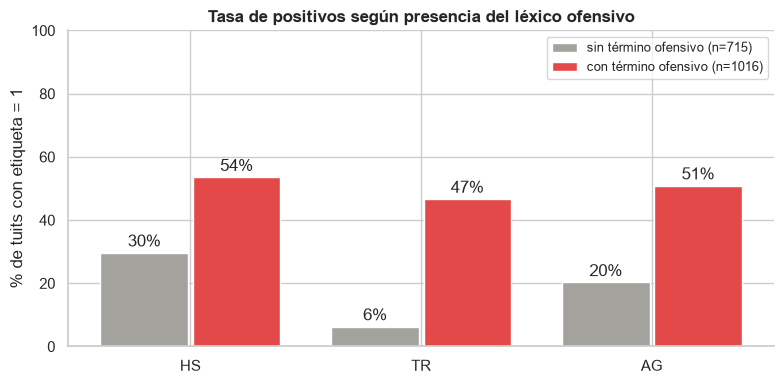

In [32]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(LABELS))
has = train_lex["any_offensive"]
r_yes = [100 * train_lex.loc[has, lab].mean() for lab in LABELS]
r_no = [100 * train_lex.loc[~has, lab].mean() for lab in LABELS]
b1 = ax.bar(x - 0.2, r_no, width=0.38, color=CLASS_COLORS[0], label=f"sin término ofensivo (n={(~has).sum()})")
b2 = ax.bar(x + 0.2, r_yes, width=0.38, color=CLASS_COLORS[1], label=f"con término ofensivo (n={has.sum()})")
ax.bar_label(b1, fmt="%.0f%%", padding=2)
ax.bar_label(b2, fmt="%.0f%%", padding=2)
ax.set(xticks=x, xticklabels=LABELS, ylabel="% de tuits con etiqueta = 1", ylim=(0, 100),
       title="Tasa de positivos según presencia del léxico ofensivo")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
savefig(fig, "lexicon_rates")
plt.show()

**Interpretación:** - El 58.7% de los tuits (1016) contiene algún término del léxico. Entre ellos la tasa de HS es del **53.5%, frente al 29.7%** en los que no lo contienen. Es una señal real pero muy imperfecta: **casi la mitad de los tuits con insulto son HS=0**.
- El léxico es más útil para **TR**: sin término ofensivo, solo el 6.3% es TR=1, y el léxico cubre el 91.3% de los TR=1. Para HS deja fuera el 28% de los positivos.
- Por término, lo que pesa es **contra quién va el insulto**. *zorra* (89.1% HS), *perra* (77.2%), *sudaca* (84.4%) y *negrata* (88.9%) son muy indicativos. En cambio, *puta/puto* (583 tuits) tiene un **40.1% de HS, por debajo de la tasa base (43.7%)**, e *hijo de puta* (121 tuits) solo un 18.2%.
- No hay formas censuradas (*p\*ta*, *put@*) en el train, así que las variantes de censura no añaden cobertura.

Un léxico bien elegido sirve como *feature* (separando insultos dirigidos a mujeres, a colectivos y genéricos), pero no puede sustituir al modelo.

## 7. Ruido de etiquetas

Ninguna anotación humana es perfecta. Buscamos dos tipos de casos sospechosos:

1. **Insulto con HS=0:** puede ser un error de etiqueta o un uso legítimo, como el insulto entre amigos, un intensificador ("*una puta vergüenza*") o un insulto sin un colectivo como objetivo. No todo insulto es discurso de odio.
2. **HS=1 sin insulto obvio:** odio expresado sin palabrotas (estereotipos, deshumanización, llamados a expulsar) o posibles errores.

También buscamos **casi-duplicados**: tuits que, tras normalizarlos (minúsculas, sin menciones, URLs, `RT` ni signos), quedan iguales. Si tienen etiquetas distintas, al menos una es inconsistente. Esto da una cota inferior del ruido.

In [33]:
show_cols = ["text", "HS", "TR", "AG"]
ins_hs0 = train_lex[train_lex["any_insult"] & (train_lex["HS"] == 0)]
print(f"Tuits con insulto general y HS=0: {len(ins_hs0)} de {train_lex['any_insult'].sum()} con insulto "
      f"({100 * len(ins_hs0) / train_lex['any_insult'].sum():.1f}%). De ellos, con AG=1: {ins_hs0['AG'].sum()} "
      f"(entre comillas en el CSV: {(ins_hs0['AG'].astype(bool) & ins_hs0['csv_quoted']).sum()})")
display(ins_hs0.sample(12, random_state=SEED)[show_cols])

Tuits con insulto general y HS=0: 466 de 981 con insulto (47.5%). De ellos, con AG=1: 2 (entre comillas en el CSV: 2)


,text,HS,TR,AG
191,PERDN SI SOY EGOSTA Y PERDN SI TE ALEJO. PERO AS ME ENSEARON A SER Y NO CONOZCO OTRA PUTA MANERA DE SER,0,0,0
230,@Ializar @lauradlcalle @VenACenarTV Es incierto! Te olvidaste lo de ZORRA! Pero bueno si t eres feliz as adelante! No voy h gastar mis energias cn alguien c...,0,0,0
110,@auronplay @Esteban_Alva_ Jajaj que gracioso kion cuando dise no pares de ablarme raul y despues callate hijo puta,0,0,0
1716,flor vigna te mereces todo la puta madre,0,0,0
274,@OneforAllDeku_ @xkingxexplosion T no me das ordenes imbcil voy a destruirle la polla a ese maldito subnormal y voy hacer las cosas a mi maldita manera! Apr...,0,0,0
1222,@_Nakoi t eres guapsimo hijo de puta,0,0,0
849,@todonoticias @jorgejorge68 Callate hijo de puta golpista.!!!,0,0,0
23,EN LA PRIMERA PARTIDA ME HE COMIDO UNA POLLA POR IMBECIL VAMOS A LA SEGUNDA https://t.co/cQvgerFbXi,0,0,0
626,@moillorens Como escuece perro. Vete a chuparla a Artur Ms o a tu Puta madre ya y callate.,0,0,0
854,La puta escena en la que la asitica salva a Finn? Pero tu eres subnormal o como va?,0,0,0


In [34]:
clean_hs1 = train_lex[~train_lex["any_offensive"] & (train_lex["HS"] == 1)]
print(f"Tuits HS=1 sin ningún término del léxico: {len(clean_hs1)} de {train['HS'].sum()} "
      f"({100 * len(clean_hs1) / train['HS'].sum():.1f}%)")
display(clean_hs1.sample(12, random_state=SEED)[show_cols])

Tuits HS=1 sin ningún término del léxico: 212 de 756 (28.0%)


,text,HS,TR,AG
244,"""""Le Pen pide a Espaa que expulse a todos los inmigrantes ilegales: Debe actuar como Italia o Australia"""""""""""""""" https://t.co/1H68z6mPVJ""""""""""""",1,0,1
1481,Para mi si quers llegar a latinoamerica no suma el discurso argento de nosotros somos descendientes d europ.. Nose un mexicano nos diria para loca somos tos...,1,0,1
1177,la pedroche que buena est y que feminista es pero la chica de tu barrio que lleva escote y falda pa salir de fiesta es una guarra,1,1,1
674,Yo siempre he pensado que en mi otra vida fui negra mamona. Ahora me toca ser una gera desabrida y sin big ass.,1,1,1
568,Hdsptm geras pelones sin cejas https://t.co/K8otT8zeuI,1,0,0
1711,@salvameoficial Tu eres el ser humano mas malo que hay en la tierra GUARRA CERDA SUCIA,1,1,1
441,Como se le ocurre ir contra la libertad y el buen Rollo! Dejad que los inmigrantes se explayen y disfruten de nuestra pasta y mujeres. https://t.co/aNAG768mBL,1,0,1
1531,A fregar guarra @Barbijaputa,1,1,1
124,Mis vecinos estaban escuchando msica al palo y pasaron de rabe a Do I Wanna Know? Literal my two moods,1,1,1
886,@JorgeMasta @elchiringuitotv Si es cierto solo les restrego la polla en la cara a todas las que estaban alli de blanco jajajjajajjajjaa me dievierte eso,1,0,1


**Interpretación:** De los 981 tuits con insulto, **466 (47.5%) tienen HS=0, y solo 2 de ellos tienen AG=1** (ambos entre comillas en el CSV). Por tanto, **AG no mide "lenguaje agresivo" en general**: un insulto agresivo sin odio hacia el colectivo se anota 000 (*"Callate hijo de puta golpista.!!!"*). La mayoría de los ejemplos con insulto y HS=0 son coherentes con esa definición: usos como intensificador (*"otra puta manera de ser"*), bromas entre amigos (*"Tu eres mi perra en beer pong"*) o insultos a hombres. Más que ruido, reflejan una **definición estrecha de HS**.

Entre los HS=1 sin término del léxico (212, el 28.0%) hay odio sin palabrotas (*"Los inmigrantes vienen a quitarnos el trabajo..."*), insultos que el léxico no cubre (*guarra*, *cerda*, *gera*) y algunos casos que parecen **errores de etiqueta**. Por ejemplo, *"Mis vecinos estaban escuchando msica... pasaron de rabe a Do I Wanna Know?"* está anotado 111.

In [35]:
def normalize(text: str) -> str:
    """Normalización para detectar casi-duplicados: minúsculas, sin menciones, URLs, RT ni signos."""
    t = strip_handles(text).lower()
    t = re.sub(r"\brt\b", " ", t)
    t = re.sub(r"[^\w\s]|_", " ", t)
    return re.sub(r"\s+", " ", t).strip()


train["norm"] = train["text"].map(normalize)
groups = train.groupby("norm").filter(lambda g: len(g) > 1)
print(f"Tuits que comparten texto normalizado con otro: {len(groups)} en {groups['norm'].nunique()} grupos")

contradictory = groups.groupby("norm").filter(lambda g: (g[LABELS].nunique() > 1).any())
print(f"Grupos con etiquetas contradictorias: {contradictory['norm'].nunique()} ({len(contradictory)} tuits)")
display(contradictory.sort_values("norm")[["id", "text", "HS", "TR", "AG"]])

Tuits que comparten texto normalizado con otro: 32 en 10 grupos
Grupos con etiquetas contradictorias: 1 (2 tuits)


,id,text,HS,TR,AG
676,23172,@mariogigasanche Tu eres mi perra,0,0,0
1650,20628,@Nayra_mex @blacknavi420 @escortsnat @Nayrazd1 Tu eres mi perra,1,1,1


La normalización exacta no detecta los casos que difieren en una o dos palabras. Como complemento comparamos todos los pares de tuits con **similitud coseno** sobre TF-IDF de n-gramas de caracteres (1 = textos idénticos) y revisamos los pares con similitud ≥ 0.9.

In [36]:
from sklearn.feature_extraction.text import TfidfVectorizer

vec_dup = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1)
X_dup = vec_dup.fit_transform(train["norm"])
sim = (X_dup @ X_dup.T).tocoo()
mask = (sim.row < sim.col) & (sim.data >= 0.9)
pairs = pd.DataFrame({"i": sim.row[mask], "j": sim.col[mask], "sim": sim.data[mask]})
pairs["etiquetas i"] = train[LABELS].astype(str).agg("".join, axis=1).values[pairs["i"]]
pairs["etiquetas j"] = train[LABELS].astype(str).agg("".join, axis=1).values[pairs["j"]]
pairs["contradicen"] = pairs["etiquetas i"] != pairs["etiquetas j"]
print(f"Pares con similitud >= 0.9: {len(pairs)} | con etiquetas distintas: {pairs['contradicen'].sum()}")

contra_pairs = pairs[pairs["contradicen"]].sort_values("sim", ascending=False)
view = pd.DataFrame({
    "sim": contra_pairs["sim"].round(3).values,
    "texto i": train["text"].values[contra_pairs["i"]], "HS TR AG i": contra_pairs["etiquetas i"].values,
    "texto j": train["text"].values[contra_pairs["j"]], "HS TR AG j": contra_pairs["etiquetas j"].values,
})
display(view.head(15))

Pares con similitud >= 0.9: 93 | con etiquetas distintas: 7


,sim,texto i,HS TR AG i,texto j,HS TR AG j
0,1.000,@mariogigasanche Tu eres mi perra,000,@Nayra_mex @blacknavi420 @escortsnat @Nayrazd1 Tu eres mi perra,111
1,0.959,@agos_goroso CALLATE HIJA DE PUTA JAJAJAJAJAJAJAJAJAJA,000,@juliesart0rio JAJAJAJAJAJA cllate puta,111
2,0.949,Mtete en tu vida negro indocumentado JAJAJAJAJJAJAJAJAJAJAJAJAJAJAJAJAJAJAJAJAJJAJAJAJAJAAJAJAJAJAJAJAJAJAJAJAJAJJA,111,@agos_goroso CALLATE HIJA DE PUTA JAJAJAJAJAJAJAJAJAJA,000
3,0.938,@agos_goroso CALLATE HIJA DE PUTA JAJAJAJAJAJAJAJAJAJA,000,@andreaacata cllate perra JAJAJAJAJAJA,111
4,0.906,@agos_goroso CALLATE HIJA DE PUTA JAJAJAJAJAJAJAJAJAJA,000,@mendezr_agus jajajajajajaja perra te lo merecas,111
5,0.904,@agos_goroso CALLATE HIJA DE PUTA JAJAJAJAJAJAJAJAJAJA,000,@SofiParias @Tomipassamonti Jajajajajajajaj callate puta dmierda,111
6,0.902,@mariogigasanche Tu eres mi perra,000,@MemeBurgos tu eres la perra https://t.co/FSN6n9BTBH,111


**Interpretación:** Hay 10 grupos de casi-duplicados exactos (32 tuits, casi todos variantes de *"Cllate perra"*). Solo **1 grupo es contradictorio**: *"Tu eres mi perra"* aparece como 000 y como 111. Por similitud de caracteres (≥ 0.9) salen 93 pares, de los que **7 tienen etiquetas distintas**. Varios son plantillas "cállate + insulto + jajaja" con etiquetas opuestas (*"CALLATE HIJA DE PUTA JAJAJA"* = 000 frente a *"cllate puta JAJAJA"* = 111), lo que muestra la subjetividad en este tipo de tuits.

La inconsistencia entre duplicados es **baja** (cota inferior de unos pocos casos en 1731). La fuente de ruido más sistemática que hemos encontrado es el **artefacto de AG en las 51 filas entre comillas**.

## 8. Train vs test

Si el test se parece al train, lo que aprendamos en validación cruzada se trasladará a Kaggle. Comparamos primero rasgos simples (longitud, menciones, URLs, caracteres no ASCII) y después hacemos una **validación adversarial**.

**Validación adversarial:** juntamos train y test, etiquetamos cada tuit según su origen (0 = train, 1 = test) y entrenamos un clasificador que intente adivinarlo. Medimos su capacidad con el **AUC** (área bajo la curva ROC): la probabilidad de que, tomando un tuit de test y uno de train al azar, el modelo asigne mayor puntuación al de test.
- **AUC ≈ 0.5**: el modelo no distingue mejor que una moneda, así que ambos conjuntos vienen de la misma distribución.
- **AUC cercano a 1**: hay diferencias sistemáticas (otro periodo, otra fuente, otra codificación), y la validación cruzada sobre train podría ser optimista.

Usamos TF-IDF de n-gramas de caracteres más regresión logística, con validación cruzada estratificada de 5 *folds*. Este modelo solo sirve como diagnóstico y no se usa para predecir las etiquetas.

split,train,test
n_chars (mediana),91.0,91.0
n_words (mediana),15.0,15.0
% con mención,47.4,45.8
% empieza con mención,40.5,39.7
% con URL,31.2,28.3
% con hashtag,9.3,9.6
% alargamiento,3.6,3.3
% risa,6.3,4.9
% tuits con no ASCII,0.0,0.5


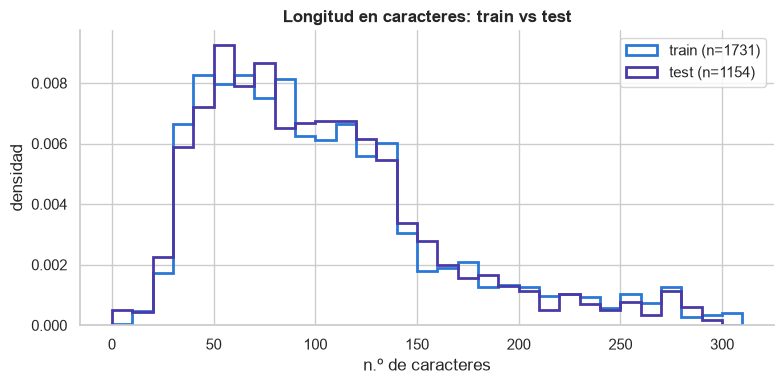

In [37]:
if HAS_TEST:
    feat_test = text_features(test["text"])
    both = pd.concat([feat.assign(split="train"), feat_test.assign(split="test")], ignore_index=True)
    both["n_nonascii"] = pd.concat([train["text"], test["text"]], ignore_index=True).map(
        lambda t: sum(ord(c) > 127 for c in t))
    comp = pd.DataFrame({
        "n_chars (mediana)": both.groupby("split")["n_chars"].median(),
        "n_words (mediana)": both.groupby("split")["n_words"].median(),
        "% con mención": 100 * both.groupby("split")["n_mentions"].apply(lambda s: (s > 0).mean()),
        "% empieza con mención": 100 * both.groupby("split")["starts_mention"].mean(),
        "% con URL": 100 * both.groupby("split")["n_urls"].apply(lambda s: (s > 0).mean()),
        "% con hashtag": 100 * both.groupby("split")["n_hashtags"].apply(lambda s: (s > 0).mean()),
        "% alargamiento": 100 * both.groupby("split")["has_elong"].mean(),
        "% risa": 100 * both.groupby("split")["has_laugh"].mean(),
        "% tuits con no ASCII": 100 * both.groupby("split")["n_nonascii"].apply(lambda s: (s > 0).mean()),
    }).T.round(1)[["train", "test"]]
    display(comp)

    fig, ax = plt.subplots(figsize=(8, 4))
    bins = np.arange(0, both["n_chars"].max() + 10, 10)
    for split in ["train", "test"]:
        ax.hist(both.loc[both.split == split, "n_chars"], bins=bins, density=True, histtype="step", lw=2,
                color=SPLIT_COLORS[split], label=f"{split} (n={(both.split == split).sum()})")
    ax.set(title="Longitud en caracteres: train vs test", xlabel="n.º de caracteres", ylabel="densidad")
    ax.legend()
    fig.tight_layout()
    savefig(fig, "train_vs_test_length")
    plt.show()
else:
    print("No hay test: se omite la comparación train vs test.")

**Interpretación:** Train y test son **muy parecidos**: misma mediana de longitud (91 caracteres, 15 palabras), menciones 47.4% frente a 45.8%, URLs 31.2% frente a 28.3%, hashtags 9.3% frente a 9.6%. Las risas son algo menos frecuentes en test (4.9% frente a 6.3%). El único carácter no ASCII del test (0.5% de los tuits) es el `¿` de `#¿NOMBRE?`. **El test no trae tildes ni ñ**, así que no hace falta igualar la codificación entre ambos conjuntos. Las distribuciones de longitud se superponen casi por completo.

Además, **21 tuits del test tienen un gemelo normalizado en train** (7 textos distintos, casi todos *"Cllate perra/puta"*).

In [38]:
if HAS_TEST:
    test["norm"] = test["text"].map(normalize)
    shared_norm = set(train["norm"]) & set(test["norm"]) - {""}
    print(f"Textos normalizados presentes en train y test: {len(shared_norm)} "
          f"({test['norm'].isin(shared_norm).sum()} tuits de test)")
    display(test.loc[test["norm"].isin(shared_norm), ["id", "text"]].head(10))

Textos normalizados presentes en train y test: 7 (21 tuits de test)


,id,text
36,20623,@Alvenef @LeaVieilletoile Cllate perra
60,20939,@TereGarciaOK CALLATE PUTA !!!!!!
108,20763,@CandeeLucero_ @MLauttaro Cllate puta
255,22448,Los sin papeles te roban el trabajo. https://t.co/OCAXJm4UH2
284,22737,@PabloAgustin @barbarammzz @MicaSuarez12 CLLATE...PERRA https://t.co/Qm6enxgxls
364,23256,@AgusManzanares En tu cara zorra
523,21509,@carlosj_almon Cllate perra
539,20898,@YazminCantuT @ClubAmerica @eduardoushito Cllate perra
618,20947,@_JBonilla_ @CanalYesTV Cllate perra
686,24936,@weni_habbo @ESHabbo @JorgeHelper @LinuXx_Habbo @DeRociodemiel @BryanBieber17HB @iMonyHabbo Cllate puta


In [39]:
if HAS_TEST:
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import StratifiedKFold, cross_val_score
    from sklearn.pipeline import make_pipeline

    adv_text = pd.concat([train["text"], test["text"]], ignore_index=True)
    adv_y = np.r_[np.zeros(len(train)), np.ones(len(test))]
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

    def adv_pipeline():
        return make_pipeline(
            TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True, lowercase=True),
            LogisticRegression(max_iter=2000, C=1.0, random_state=SEED),
        )

    auc_raw = cross_val_score(adv_pipeline(), adv_text, adv_y, cv=cv, scoring="roc_auc")
    # Variante sin caracteres no ASCII ni '#¿NOMBRE?', para descartar que el AUC lo expliquen esos artefactos
    adv_text_ascii = adv_text.str.replace("#¿NOMBRE?", " ", regex=False).map(
        lambda t: t.encode("ascii", "ignore").decode())
    auc_ascii = cross_val_score(adv_pipeline(), adv_text_ascii, adv_y, cv=cv, scoring="roc_auc")
    print(f"AUC adversarial (texto original):      {auc_raw.mean():.3f} ± {auc_raw.std():.3f}  folds={np.round(auc_raw, 3)}")
    print(f"AUC adversarial (sin no ASCII/#NOMBRE): {auc_ascii.mean():.3f} ± {auc_ascii.std():.3f}  folds={np.round(auc_ascii, 3)}")

    # n-gramas que más empujan hacia "test" y hacia "train" (modelo ajustado con todos los datos, solo para inspección)
    adv = adv_pipeline().fit(adv_text, adv_y)
    names = adv[0].get_feature_names_out()
    coefs = adv[1].coef_[0]
    idx = np.argsort(coefs)
    display(pd.DataFrame({"hacia train": [repr(names[i]) for i in idx[:12]],
                          "coef train": coefs[idx[:12]].round(2),
                          "hacia test": [repr(names[i]) for i in idx[::-1][:12]],
                          "coef test": coefs[idx[::-1][:12]].round(2)}))

AUC adversarial (texto original):      0.504 ± 0.023  folds=[0.542 0.515 0.485 0.476 0.504]
AUC adversarial (sin no ASCII/#NOMBRE): 0.505 ± 0.023  folds=[0.542 0.515 0.488 0.475 0.503]


,hacia train,coef train,hacia test,coef test
0,'as ',-0.66,'amo',0.61
1,'tu ',-0.63,' @_',0.61
2,'ec',-0.61,'con ',0.56
3,'u ',-0.61,' - ',0.56
4,' tu ',-0.61,'it',0.56
5,' esc',-0.60,'po',0.56
6,'uer',-0.59,'@_',0.56
7,' es',-0.58,' ha',0.54
8,'cin',-0.56,' dij',0.54
9,'i ',-0.55,' ex',0.52


**Interpretación:** **AUC adversarial = 0.504 ± 0.023** (0.505 tras eliminar los caracteres no ASCII y las celdas `#¿NOMBRE?`). El clasificador no distingue train de test mejor que el azar, así que ambos conjuntos vienen de la **misma distribución**. Es razonable esperar que la validación cruzada sobre train sea un buen indicador del resultado en Kaggle. Los n-gramas con mayor peso tienen coeficientes pequeños (|coef| < 0.7) y no forman ningún patrón temático.

## 9. Conclusiones y decisiones para el preprocesamiento (02)

### Hallazgos clave

- **Datos:** 1731 filas en train y 1154 en test. Las 1228 del visor se explican por una fila con comillas mal formadas en el id (`"22621`), que `load_train()` corrige.
- **Etiquetas:** HS 43.7%, TR 30.0%, AG 38.2%. **TR=1 ⇒ HS=1 siempre.** AG=1 ⇒ HS=1 salvo 26 casos, y esos 26 son un **artefacto**: las 51 filas que el CSV escribió entre comillas tienen *todas* AG=1, incluidos titulares neutros. Sin ellas, la jerarquía es estricta.
- **Codificación:** el train y el test **borraron todos los caracteres no ASCII** (tildes, ñ, ü, ¿, ¡, emojis). Es sistemático y es igual en ambos conjuntos. *cllate* convive con *callate* y *rabe* con *arabe*: el vocabulario se fragmenta. Al menos el 43.3% de los tuits tiene alguna palabra dañada.
- **Rasgos superficiales:** las menciones (47.4%) y las URLs (31.2%) son frecuentes. Los alargamientos de letra son raros (**3.6%**, no 19%). TR=1 son respuestas cortas a una persona (empiezan con mención: 65% frente a 30%) y los negativos se parecen más a titulares (URL, hashtag).
- **Vocabulario:** HS se concentra en insultos contra **mujeres** (*perra*, *zorra*, *guarra*) y términos contra **migrantes** (*sudacas*, *moros*, *subsaharianos*). *puta* e *hijo de puta* no indican HS. Las plantillas "cállate + insulto" y "eres una + insulto" marcan TR. El patrón encaja con una anotación al estilo **HatEval 2019** (odio contra mujeres e inmigrantes).
- **spaCy (`es_core_news_sm` 3.8.0, GPL 3.0):**
  - Tarda ≈1.5 s en todo el train.
  - En tuits falla mucho: toma por nombre propio cualquier palabra con mayúscula (13.5% de los tokens, 5.3% en minúsculas), no reconoce los imperativos (*callate* → sustantivo o *callatar*) e inventa lemas (*rabir*, *perrar*, *vetir*).
  - La hipótesis de imperativos y segunda persona **se confirma con un léxico**: imperativo en el 45.3% de TR=1 frente al 13.7% de TR=0. Con `Mood=Imp` de spaCy no se ve.
  - Los lemas reducen el vocabulario un 14.5%, pero no discriminan mejor que las palabras: *eres* se diluye en *ser*.
- **Léxico:** cubre el 72% de HS=1 y el 91% de TR=1, pero el 47.5% de los tuits con insulto es HS=0. Sirve como *feature*, no como regla.
- **Ruido:** la contradicción entre casi-duplicados es baja. Hay casos dudosos aislados, y el problema sistemático es el artefacto de AG.
- **Train vs test:** misma distribución (**AUC adversarial 0.50**). El test tampoco trae tildes. Tiene 6 filas `#¿NOMBRE?` sin texto, 34 tuits con `;` o `"` y 21 tuits con un gemelo en train.

### Decisiones propuestas para `02_preprocesamiento`

1. **Carga:** usar siempre `load_train()` / `load_test()` de `common.py`. No modificar `data/`.
2. **Artefactos del CSV:** colapsar las comillas duplicadas (`""` → `"` y quitar las comillas exteriores), decodificar las entidades HTML (`html.unescape`) y marcar las 6 filas `#¿NOMBRE?` como texto vacío con una predicción por defecto (la combinación mayoritaria es `000`).
3. **Codificación:** a cualquier texto externo (léxicos, corpus) se le aplica **la misma transformación que sufrió el train**: borrar los caracteres no ASCII, sin transliterar (*cállate* → *cllate*). Así coinciden con nuestros datos.
4. **Fragmentación:** comparar experimentalmente (a) dejar el texto tal cual y confiar en los n-gramas de caracteres, frente a (b) restaurar las ~20 formas dañadas más frecuentes (*cllate* → *callate*, *rabe* → *arabe*, *espaa* → *espana*, *ms* → *mas*) más las reglas *-cin* → *-cion* y *-sin* → *-sion*.
5. **Normalización de tuits:** menciones → `@USER`, URLs → `URL`, quitar `#` y conservar la palabra, eliminar `RT`, pasar a minúsculas, reducir los alargamientos a 2 repeticiones y unificar las risas en un token `jaja`. **No quitar stopwords** (*tu*, *eres* y *te* son informativas para TR).
6. **Features candidatas:** TF-IDF de n-gramas de caracteres (más robusto al borrado) y de palabras (uni y bigramas). Rasgos superficiales: longitud, empieza con mención, número de menciones, URL, hashtag, risa y proporción de mayúsculas. Indicadores de léxico separados por tipo (contra mujeres, contra colectivos, genéricos).
7. **Coherencia de etiquetas:** modelar en cascada o posprocesar para que HS=0 ⇒ TR=0 y AG=0.
8. **Validación:** k-fold estratificado por combinación de etiquetas con `SEED`, manteniendo los casi-duplicados (texto normalizado) en el mismo fold para no filtrar información.
9. **Lematización (nota):**
   - **¿Conviene?** Sí como vista **complementaria**, no como sustituto de las palabras. Las palabras y los n-gramas de caracteres siguen siendo la base, y los lemas se añaden como TF-IDF aparte solo si mejoran el F1 en validación cruzada. Si se usa, hay que conservar la forma original de los pronombres y verbos de segunda persona (*eres*, *te*), o añadir aparte un rasgo de segunda persona, porque *ser* y *tú* diluyen esa señal.
   - **¿Antes o después de normalizar?** **Después** de la normalización básica y **antes** de los ajustes finales:
     1. limpieza (URLs, menciones, comillas, entidades HTML);
     2. minúsculas;
     3. reducir alargamientos y unificar risas;
     4. restaurar las formas dañadas frecuentes;
     5. **spaCy** (solo lema, POS y morfología);
     6. corregir los lemas con un diccionario propio para los errores conocidos (*callate*, *cllate*, *cállate* → *callar*; *vete* → *ir*; *perrar* → *perra*; *rabir* → *árabe*).
   - **Imperativo y segunda persona:** construirlos con **reglas y léxico**, no con `Mood=Imp`. `Person=2` de spaCy es aceptable como complemento.
   - **Coste:** ≈1.5 s para todo el train y salida determinista, así que se calcula **una vez** y se guarda en caché (ubicación por decidir; los CSV de `data/` no se tocan). No se recalcula por fold.
   - **Restricciones:** nunca usar vectores (`token.vector`, `doc.vector`), NER ni clasificación de texto. Citar el modelo y su licencia (GPL 3.0) en el informe.

### Preguntas abiertas

- **¿F1 macro o micro?** Cambia cómo se ajustan los umbrales de cada etiqueta.
- **¿Qué hacer con el artefacto de AG (51 filas)?** Opciones: corregir AG=0 cuando HS=0, excluir esas filas del entrenamiento de AG o dejarlas como están. ¿Es legítimo **aprovechar** el patrón en los 34 tuits del test con `;` o `"`? Es un artefacto del archivo, no lenguaje, así que conviene consultarlo con el profesor antes de usarlo.
- **¿El corpus deriva de HatEval 2019?** Si es así, usar HatEval como corpus externo podría incluir los propios tuits del test. Habría que confirmarlo y, en ese caso, no usarlo.
- ¿Merece la pena una restauración más amplia de tildes con un diccionario externo (con licencia citada), o basta con los n-gramas de caracteres?
- ¿La licencia GPL 3.0 del modelo de spaCy tiene alguna implicación para la entrega (por ejemplo, si se publica el código)? Usarlo como herramienta no parece problemático, pero conviene confirmarlo.
- ¿Se usa la etiqueta de train en los 21 tuits del test que tienen un gemelo exacto normalizado, o se deja que el modelo decida?